# RUL Prediction — NASA IMS Bearing Dataset
### Using PCA + Health Indicator + Threshold + RUL

## Step 1: Load Data

NASA IMS Bearing dataset (2nd_test).
Each file = one time snapshot of all 4 bearings.
We pick **Bearing 1** (column 0).
Sampling frequency = 20,000 Hz.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import skew, kurtosis
from scipy.fft import fft, fftfreq

In [3]:
data_dir = Path(
    "/Users/maramruthvi/.cache/kagglehub/datasets/"
    "vinayak123tyagi/bearing-dataset/versions/1/"
    "2nd_test/2nd_test"
)

Fs=20000  
bearing_col = 0   
data_paths = sorted(data_dir.glob("*"))
print("Total files:", len(data_paths))
print("First file :", data_paths[0].name)
print("Last file  :", data_paths[-1].name)

Total files: 984
First file : 2004.02.12.10.32.39
Last file  : 2004.02.19.06.22.39


In [4]:

all_segments = []
for fp in data_paths:
    raw = np.loadtxt(fp)
    all_segments.append(raw[:, bearing_col])

vibration = np.concatenate(all_segments)
time = np.arange(len(vibration)) / Fs

print("Vibration shape:", vibration.shape)
print("Total duration :", round(time[-1], 1), "seconds")

Vibration shape: (20152320,)
Total duration : 1007.6 seconds


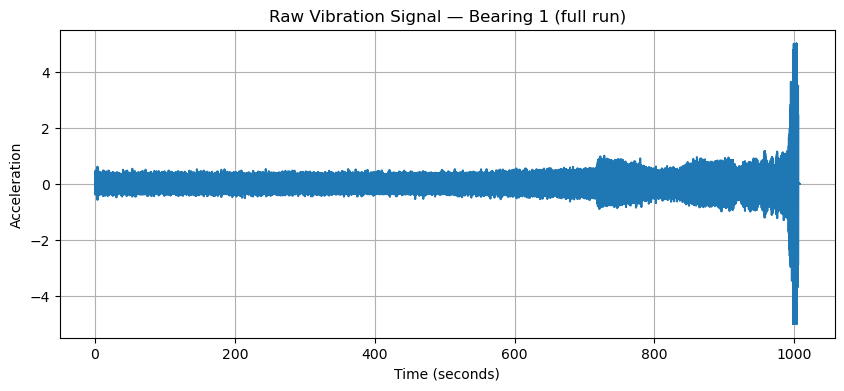

In [5]:
plt.figure(figsize=(10,4))
plt.plot(time, vibration)
plt.title("Raw Vibration Signal — Bearing 1 (full run)")
plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration")
plt.grid(True)
plt.show()

In [6]:
print("Sampling Frequency:", Fs, "Hz")
print("Samples per file  :", len(all_segments[0]))
print("Number of files   :", len(data_paths))

Sampling Frequency: 20000 Hz
Samples per file  : 20480
Number of files   : 984


## Step 2: Windowing

We divide the long vibration signal into windows.
Each window = one sample. From each window we extract features.

One file = ~1 second of data.
We use **window = 1 file size** so each window = one snapshot.

In [7]:
fs = 20000
window_seconds = 5
window_size = fs * window_seconds  
step = window_size // 2

print("Window size (samples):", window_size)
print("Window size (seconds):", window_seconds)
print("Step size (samples):", step)


Window size (samples): 100000
Window size (seconds): 5
Step size (samples): 50000


In [8]:
time_final = []

for i in range(0, len(vibration) - window_size, step):
    t = time[i + window_size // 2]
    time_final.append(t)

time_final = np.array(time_final)

print("Total windows:", len(time_final))

Total windows: 402


## Step 3: Feature Extraction

We extract 3 types of features from each window:
- **Time Domain** — 12 features
- **Frequency Domain** — 10 features
- **Time-Frequency (Wavelet)** — 5 features

Total = 27 features per window

### 3A — Time Domain Features (12)

In [9]:
time_features = {}

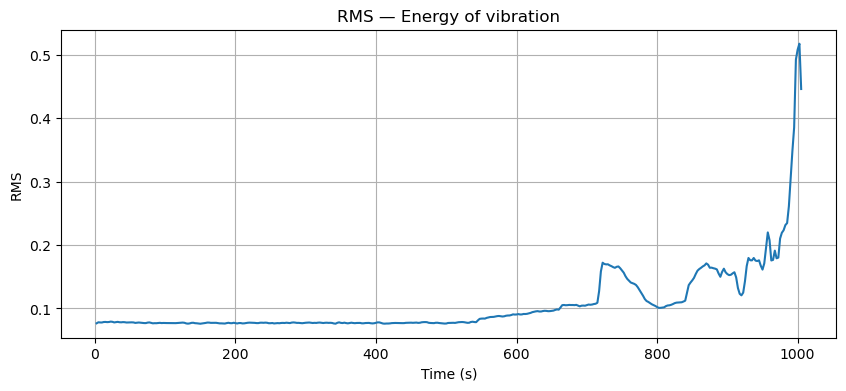

In [10]:
# 1. RMS
rms = []
for i in range(0, len(vibration) - window_size, step):
    seg = vibration[i:i+window_size]
    rms.append(np.sqrt(np.mean(seg**2)))
rms = np.array(rms)
time_features["RMS"] = rms

plt.figure(figsize=(10,4))
plt.plot(time_final, rms)
plt.title("RMS — Energy of vibration")
plt.xlabel("Time (s)"); plt.ylabel("RMS")
plt.grid(True)
plt.show()

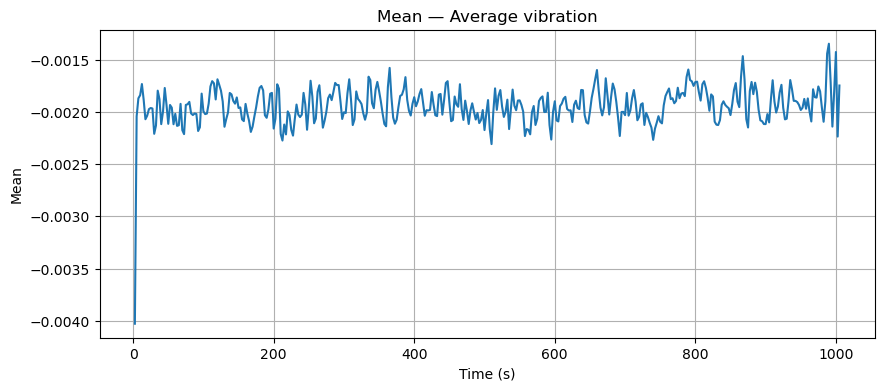

In [11]:
# 2. Mean
mean_vals = []
for i in range(0, len(vibration) - window_size, step):
    seg = vibration[i:i+window_size]
    mean_vals.append(np.mean(seg))
mean_vals = np.array(mean_vals)
time_features["Mean"] = mean_vals

plt.figure(figsize=(10,4))
plt.plot(time_final, mean_vals)
plt.title("Mean — Average vibration")
plt.xlabel("Time (s)"); plt.ylabel("Mean")
plt.grid(True)
plt.show()

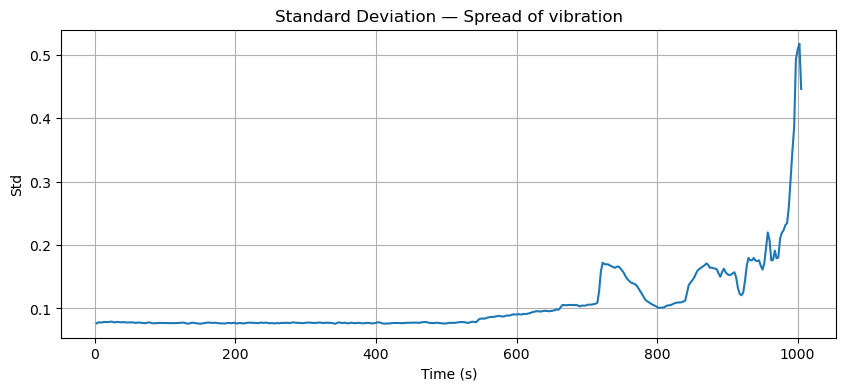

In [12]:
# 3. Standard Deviation
std_vals = []
for i in range(0, len(vibration) - window_size, step):
    seg = vibration[i:i+window_size]
    std_vals.append(np.std(seg))
std_vals = np.array(std_vals)
time_features["Std"] = std_vals

plt.figure(figsize=(10,4))
plt.plot(time_final, std_vals)
plt.title("Standard Deviation — Spread of vibration")
plt.xlabel("Time (s)"); plt.ylabel("Std")
plt.grid(True)
plt.show()

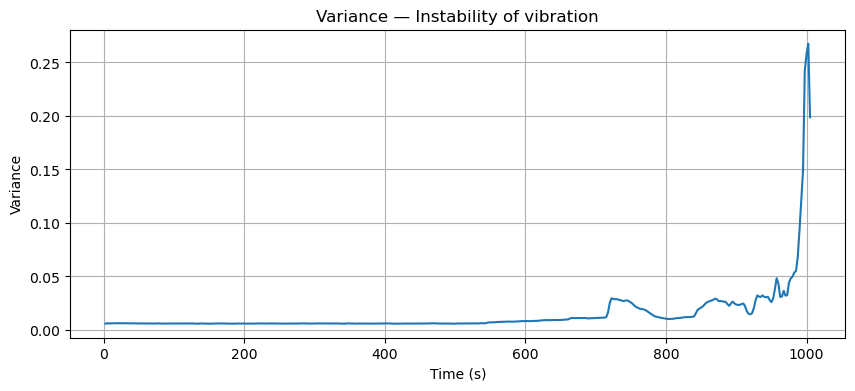

In [13]:
# 4. Variance
var_vals = []
for i in range(0, len(vibration) - window_size, step):
    seg = vibration[i:i+window_size]
    var_vals.append(np.var(seg))
var_vals = np.array(var_vals)
time_features["Variance"] = var_vals

plt.figure(figsize=(10,4))
plt.plot(time_final, var_vals)
plt.title("Variance — Instability of vibration")
plt.xlabel("Time (s)"); plt.ylabel("Variance")
plt.grid(True)
plt.show()

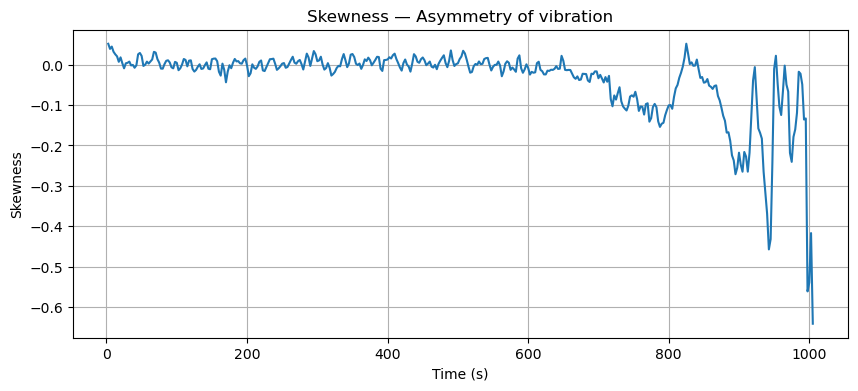

In [14]:
# 5. Skewness
skew_vals = []
for i in range(0, len(vibration) - window_size, step):
    seg = vibration[i:i+window_size]
    skew_vals.append(skew(seg))
skew_vals = np.array(skew_vals)
time_features["Skewness"] = skew_vals

plt.figure(figsize=(10,4))
plt.plot(time_final, skew_vals)
plt.title("Skewness — Asymmetry of vibration")
plt.xlabel("Time (s)"); plt.ylabel("Skewness")
plt.grid(True)
plt.show()

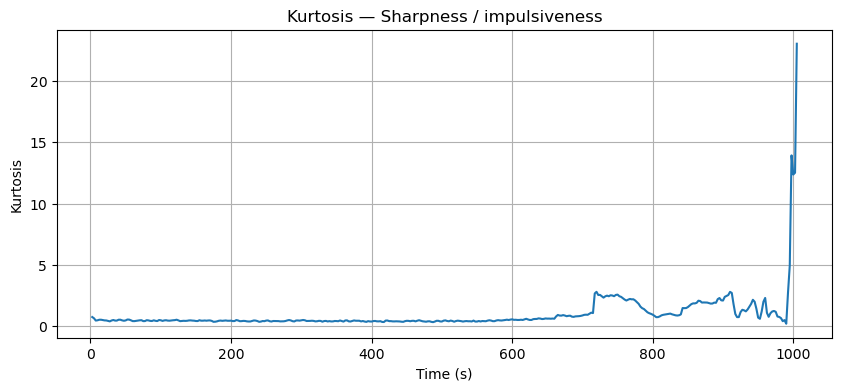

In [15]:
# 6. Kurtosis
kurt_vals = []
for i in range(0, len(vibration) - window_size, step):
    seg = vibration[i:i+window_size]
    kurt_vals.append(kurtosis(seg))
kurt_vals = np.array(kurt_vals)
time_features["Kurtosis"] = kurt_vals

plt.figure(figsize=(10,4))
plt.plot(time_final, kurt_vals)
plt.title("Kurtosis — Sharpness / impulsiveness")
plt.xlabel("Time (s)"); plt.ylabel("Kurtosis")
plt.grid(True)
plt.show()

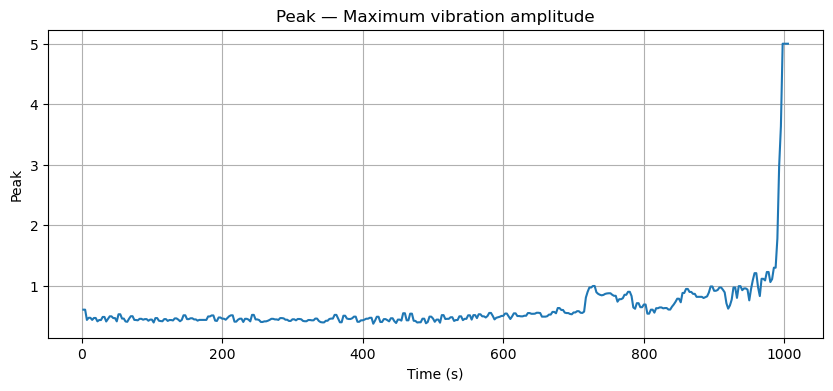

In [16]:
# 7. Peak
peak_vals = []
for i in range(0, len(vibration) - window_size, step):
    seg = vibration[i:i+window_size]
    peak_vals.append(np.max(np.abs(seg)))
peak_vals = np.array(peak_vals)
time_features["Peak"] = peak_vals

plt.figure(figsize=(10,4))
plt.plot(time_final, peak_vals)
plt.title("Peak — Maximum vibration amplitude")
plt.xlabel("Time (s)"); plt.ylabel("Peak")
plt.grid(True)
plt.show()

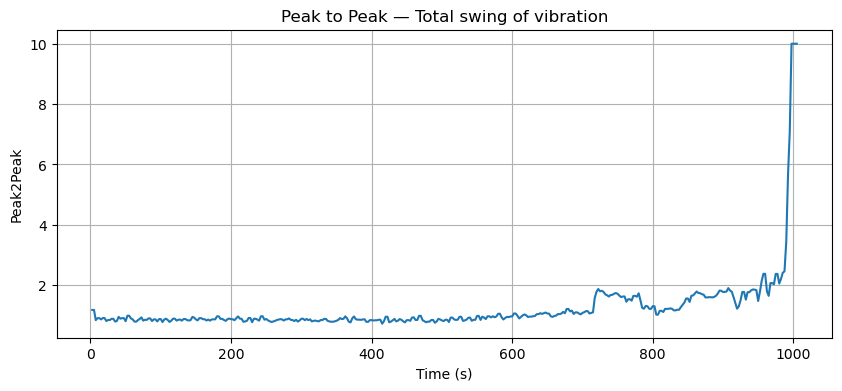

In [17]:
# 8. Peak to Peak
ptp_vals = []
for i in range(0, len(vibration) - window_size, step):
    seg = vibration[i:i+window_size]
    ptp_vals.append(np.ptp(seg))
ptp_vals = np.array(ptp_vals)
time_features["Peak2Peak"] = ptp_vals

plt.figure(figsize=(10,4))
plt.plot(time_final, ptp_vals)
plt.title("Peak to Peak — Total swing of vibration")
plt.xlabel("Time (s)"); plt.ylabel("Peak2Peak")
plt.grid(True)
plt.show()

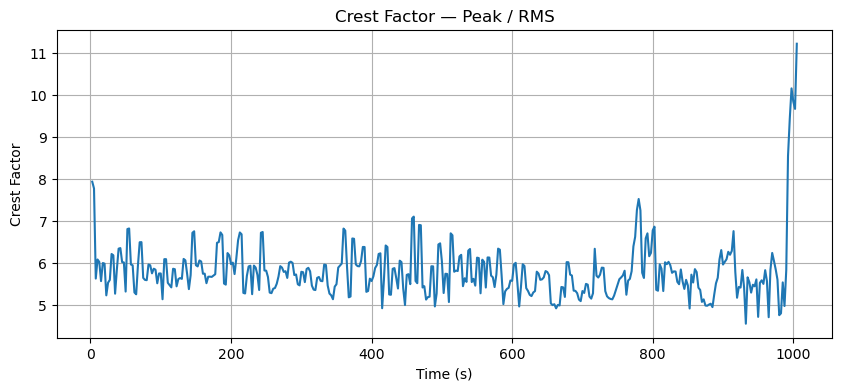

In [18]:
# 9. Crest Factor
crest_vals = []
for i in range(0, len(vibration) - window_size, step):
    seg = vibration[i:i+window_size]
    rms_seg = np.sqrt(np.mean(seg**2))
    crest_vals.append(np.max(np.abs(seg)) / (rms_seg + 1e-12))
crest_vals = np.array(crest_vals)
time_features["CrestFactor"] = crest_vals

plt.figure(figsize=(10,4))
plt.plot(time_final, crest_vals)
plt.title("Crest Factor — Peak / RMS")
plt.xlabel("Time (s)"); plt.ylabel("Crest Factor")
plt.grid(True)
plt.show()

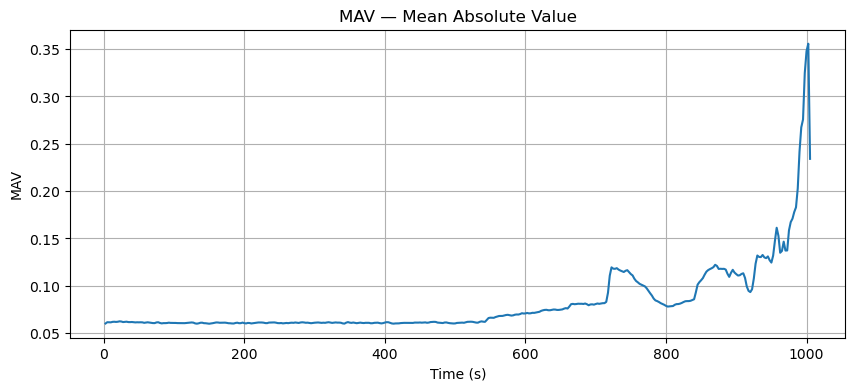

In [19]:
# 10. Mean Absolute Value (MAV)
mav_vals = []
for i in range(0, len(vibration) - window_size, step):
    seg = vibration[i:i+window_size]
    mav_vals.append(np.mean(np.abs(seg)))
mav_vals = np.array(mav_vals)
time_features["MAV"] = mav_vals

plt.figure(figsize=(10,4))
plt.plot(time_final, mav_vals)
plt.title("MAV — Mean Absolute Value")
plt.xlabel("Time (s)"); plt.ylabel("MAV")
plt.grid(True)
plt.show()

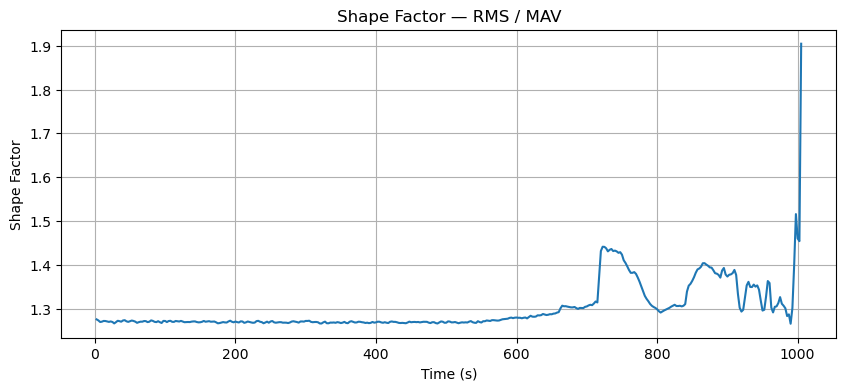

In [20]:
# 11. Shape Factor (RMS / MAV)
sf_vals = []
for i in range(0, len(vibration) - window_size, step):
    seg = vibration[i:i+window_size]
    rms_seg = np.sqrt(np.mean(seg**2))
    mav_seg = np.mean(np.abs(seg))
    sf_vals.append(rms_seg / (mav_seg + 1e-12))
sf_vals = np.array(sf_vals)
time_features["ShapeFactor"] = sf_vals

plt.figure(figsize=(10,4))
plt.plot(time_final, sf_vals)
plt.title("Shape Factor — RMS / MAV")
plt.xlabel("Time (s)"); plt.ylabel("Shape Factor")
plt.grid(True)
plt.show()

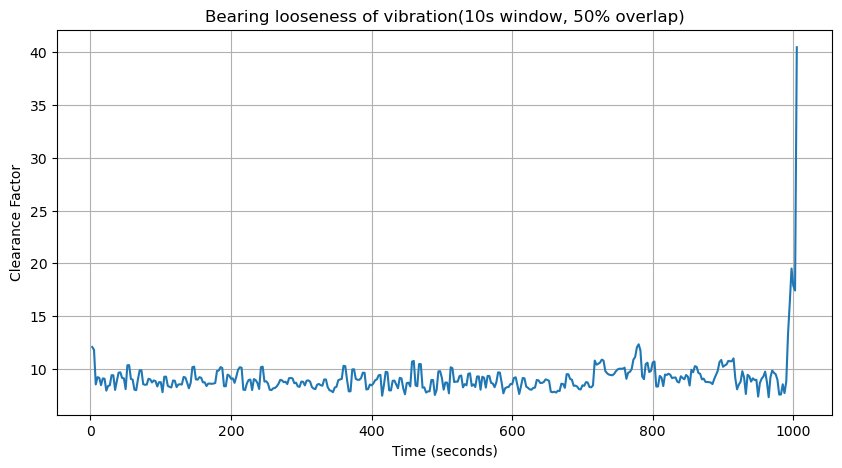

In [21]:

cf=[]
count=0

for i in range(0,len(vibration)-window_size,step):
    segment=vibration[i:i+window_size]
    cf_val=np.max(np.abs(segment))/(np.mean(np.sqrt(np.abs(segment)))**2)
    cf.append(cf_val)
cf=np.array(cf)
time_features["ClearanceFactor"] =cf


plt.figure(figsize=(10,5))
plt.plot(time_final,cf)
plt.xlabel("Time (seconds)")
plt.ylabel("Clearance Factor")
plt.title("Bearing looseness of vibration(10s window, 50% overlap)")
plt.grid(True)
plt.show()

In [22]:
# Build time-domain DataFrame
time_df = pd.DataFrame(time_features)
time_df["time"] = time_final
print("Time domain features shape:", time_df.shape)
time_df.head()

Time domain features shape: (402, 13)


,RMS,Mean,Std,Variance,Skewness,Kurtosis,Peak,Peak2Peak,CrestFactor,MAV,ShapeFactor,ClearanceFactor,time
0,0.076604,-0.004030,0.076497,0.005852,0.051467,0.733794,0.608,1.184,7.936974,0.060066,1.275328,12.057610,2.5
1,0.078190,-0.002040,0.078163,0.006110,0.038836,0.629359,0.608,1.184,7.775928,0.061425,1.272938,11.787652,5.0
2,0.077893,-0.001867,0.077871,0.006064,0.044530,0.446463,0.439,0.847,5.635931,0.061364,1.269359,8.510174,7.5
3,0.077839,-0.001838,0.077817,0.006056,0.031762,0.466530,0.474,0.913,6.089490,0.061285,1.270122,9.200399,10.0
4,0.078591,-0.001731,0.078572,0.006174,0.025385,0.512199,0.474,0.913,6.031211,0.061795,1.271795,9.129125,12.5


### 3B — Frequency Domain Features (10)

In [23]:
freq_features = {}

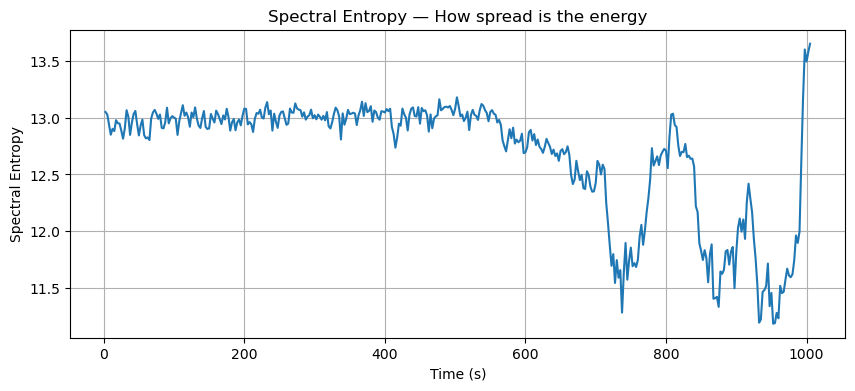

In [24]:
# 1. Spectral Entropy
spec_entropy = []
for i in range(0, len(vibration) - window_size, step):
    seg = vibration[i:i+window_size]
    spectrum = np.abs(fft(seg))[:window_size//2]
    psd = spectrum**2
    psd_norm = psd / (np.sum(psd) + 1e-12)
    entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12))
    spec_entropy.append(entropy)
spec_entropy = np.array(spec_entropy)
freq_features["SpectralEntropy"] = spec_entropy

plt.figure(figsize=(10,4))
plt.plot(time_final, spec_entropy)
plt.title("Spectral Entropy — How spread is the energy")
plt.xlabel("Time (s)"); plt.ylabel("Spectral Entropy")
plt.grid(True)
plt.show()

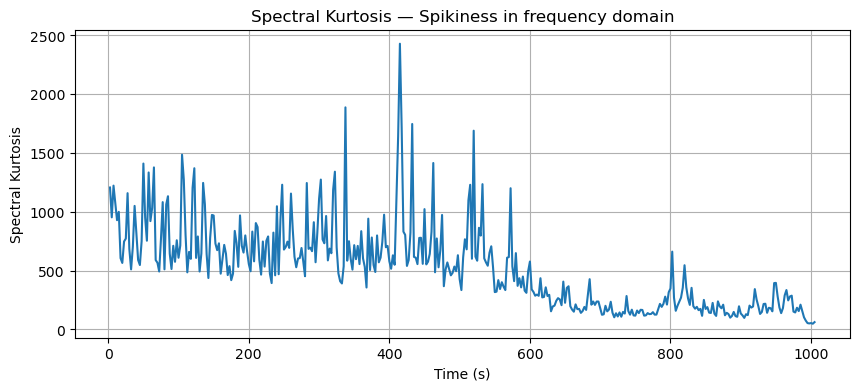

In [25]:
# 2. Spectral Kurtosis
spec_kurt = []
for i in range(0, len(vibration) - window_size, step):
    seg = vibration[i:i+window_size]
    spectrum = np.abs(fft(seg))[:window_size//2]
    spec_kurt.append(kurtosis(spectrum))
spec_kurt = np.array(spec_kurt)
freq_features["SpectralKurtosis"] = spec_kurt

plt.figure(figsize=(10,4))
plt.plot(time_final, spec_kurt)
plt.title("Spectral Kurtosis — Spikiness in frequency domain")
plt.xlabel("Time (s)"); plt.ylabel("Spectral Kurtosis")
plt.grid(True)
plt.show()

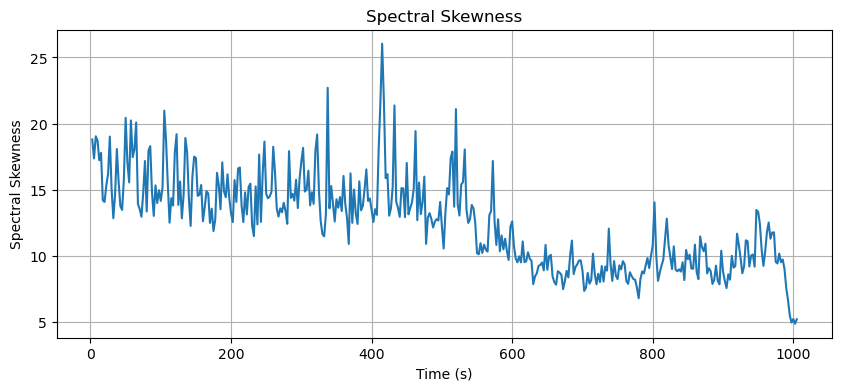

In [26]:
# 3. Spectral Skewness
spec_skew = []
for i in range(0, len(vibration) - window_size, step):
    seg = vibration[i:i+window_size]
    spectrum = np.abs(fft(seg))[:window_size//2]
    spec_skew.append(skew(spectrum))
spec_skew = np.array(spec_skew)
freq_features["SpectralSkewness"] = spec_skew

plt.figure(figsize=(10,4))
plt.plot(time_final, spec_skew)
plt.title("Spectral Skewness")
plt.xlabel("Time (s)"); plt.ylabel("Spectral Skewness")
plt.grid(True)
plt.show()

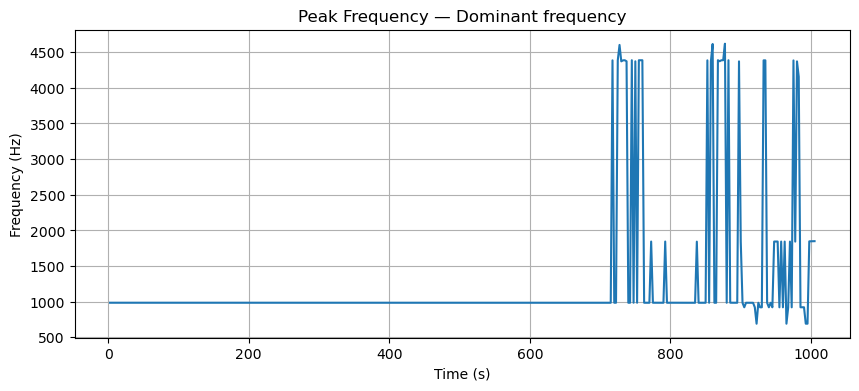

In [27]:
# 4. Peak Frequency
peak_freq = []
for i in range(0, len(vibration) - window_size, step):
    seg = vibration[i:i+window_size]
    spectrum = np.abs(fft(seg))[:window_size//2]
    freqs    = fftfreq(window_size, d=1/Fs)[:window_size//2]
    peak_freq.append(freqs[np.argmax(spectrum)])
peak_freq = np.array(peak_freq)
freq_features["PeakFreq"] = peak_freq

plt.figure(figsize=(10,4))
plt.plot(time_final, peak_freq)
plt.title("Peak Frequency — Dominant frequency")
plt.xlabel("Time (s)"); plt.ylabel("Frequency (Hz)")
plt.grid(True)
plt.show()

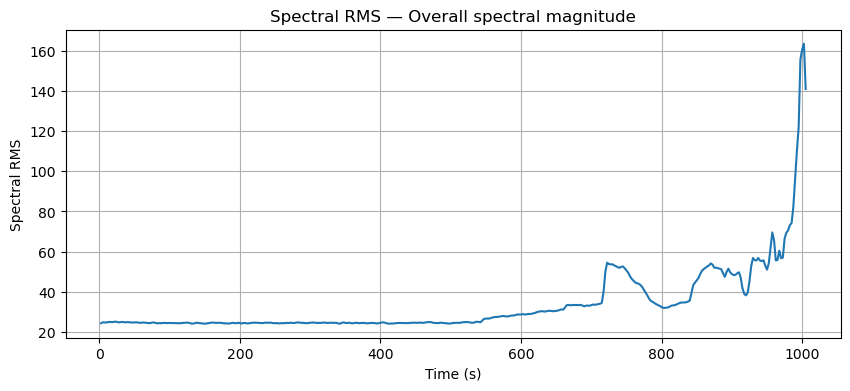

In [28]:
# 5. Spectral RMS
spec_rms = []
for i in range(0, len(vibration) - window_size, step):
    seg = vibration[i:i+window_size]
    spectrum = np.abs(fft(seg))[:window_size//2]
    spec_rms.append(np.sqrt(np.mean(spectrum**2)))
spec_rms = np.array(spec_rms)
freq_features["SpectralRMS"] = spec_rms

plt.figure(figsize=(10,4))
plt.plot(time_final, spec_rms)
plt.title("Spectral RMS — Overall spectral magnitude")
plt.xlabel("Time (s)"); plt.ylabel("Spectral RMS")
plt.grid(True)
plt.show()

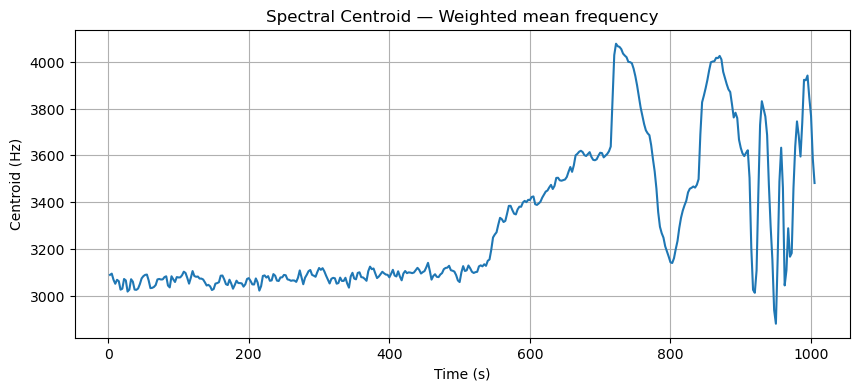

In [29]:
# 6. Spectral Centroid
spec_centroid = []
for i in range(0, len(vibration) - window_size, step):
    seg = vibration[i:i+window_size]
    spectrum = np.abs(fft(seg))[:window_size//2]
    freqs    = fftfreq(window_size, d=1/Fs)[:window_size//2]
    psd      = spectrum**2
    centroid = np.sum(freqs * psd) / (np.sum(psd) + 1e-12)
    spec_centroid.append(centroid)
spec_centroid = np.array(spec_centroid)
freq_features["SpectralCentroid"] = spec_centroid

plt.figure(figsize=(10,4))
plt.plot(time_final, spec_centroid)
plt.title("Spectral Centroid — Weighted mean frequency")
plt.xlabel("Time (s)"); plt.ylabel("Centroid (Hz)")
plt.grid(True)
plt.show()

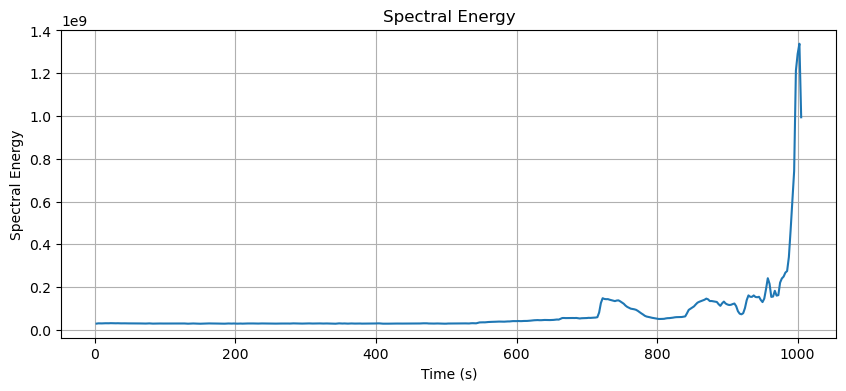

In [30]:
# 7. Spectral Energy
spec_energy = []
for i in range(0, len(vibration) - window_size, step):
    seg = vibration[i:i+window_size]
    spectrum = np.abs(fft(seg))[:window_size//2]
    spec_energy.append(np.sum(spectrum**2))
spec_energy = np.array(spec_energy)
freq_features["SpectralEnergy"] = spec_energy

plt.figure(figsize=(10,4))
plt.plot(time_final, spec_energy)
plt.title("Spectral Energy")
plt.xlabel("Time (s)"); plt.ylabel("Spectral Energy")
plt.grid(True)
plt.show()

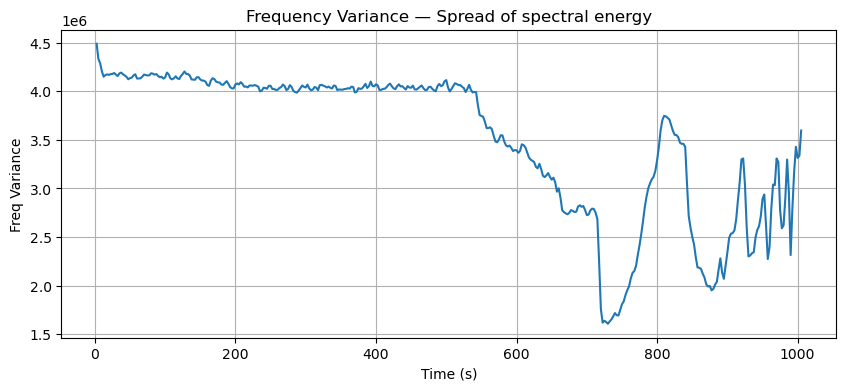

In [31]:
# 8. Frequency Variance
freq_var = []
for i in range(0, len(vibration) - window_size, step):
    seg = vibration[i:i+window_size]
    spectrum = np.abs(fft(seg))[:window_size//2]
    freqs    = fftfreq(window_size, d=1/Fs)[:window_size//2]
    psd      = spectrum**2
    centroid = np.sum(freqs * psd) / (np.sum(psd) + 1e-12)
    f_var    = np.sum(((freqs - centroid)**2) * psd) / (np.sum(psd) + 1e-12)
    freq_var.append(f_var)
freq_var = np.array(freq_var)
freq_features["FreqVariance"] = freq_var

plt.figure(figsize=(10,4))
plt.plot(time_final, freq_var)
plt.title("Frequency Variance — Spread of spectral energy")
plt.xlabel("Time (s)"); plt.ylabel("Freq Variance")
plt.grid(True)
plt.show()

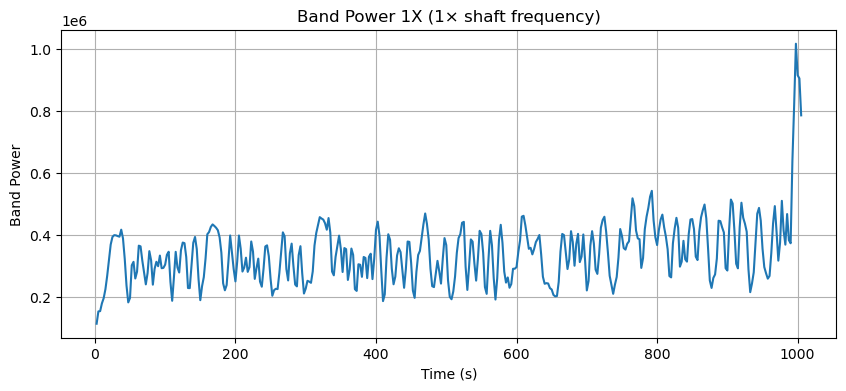

In [32]:
# 9. Band Power 1X (1 × shaft speed = 30 Hz band ±5 Hz)
shaft_hz = 30  

bp1x = []
for i in range(0, len(vibration) - window_size, step):
    seg = vibration[i:i+window_size]
    spectrum = np.abs(fft(seg))[:window_size//2]
    freqs    = fftfreq(window_size, d=1/Fs)[:window_size//2]
    psd      = spectrum**2
    mask     = (freqs >= shaft_hz - 5) & (freqs <= shaft_hz + 5)
    bp1x.append(np.sum(psd[mask]) if mask.any() else 0.0)
bp1x = np.array(bp1x)
freq_features["BandPower1X"] = bp1x

plt.figure(figsize=(10,4))
plt.plot(time_final, bp1x)
plt.title("Band Power 1X (1× shaft frequency)")
plt.xlabel("Time (s)"); plt.ylabel("Band Power")
plt.grid(True)
plt.show()

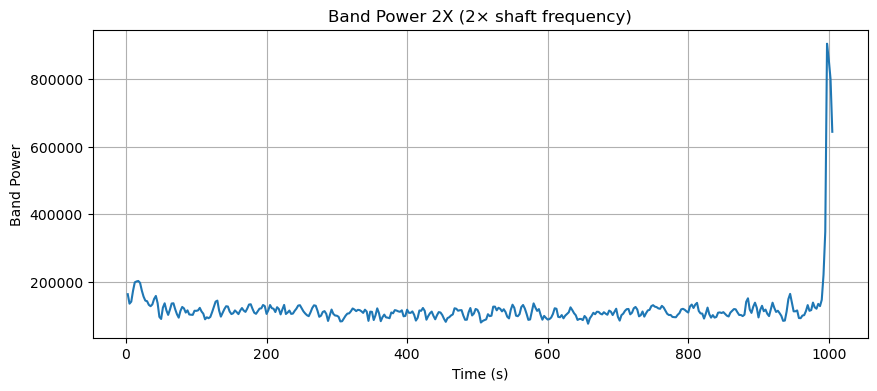

In [33]:
# 10. Band Power 2X (2 × shaft speed)
bp2x = []
for i in range(0, len(vibration) - window_size, step):
    seg = vibration[i:i+window_size]
    spectrum = np.abs(fft(seg))[:window_size//2]
    freqs    = fftfreq(window_size, d=1/Fs)[:window_size//2]
    psd      = spectrum**2
    mask     = (freqs >= 2*shaft_hz - 5) & (freqs <= 2*shaft_hz + 5)
    bp2x.append(np.sum(psd[mask]) if mask.any() else 0.0)
bp2x = np.array(bp2x)
freq_features["BandPower2X"] = bp2x

plt.figure(figsize=(10,4))
plt.plot(time_final, bp2x)
plt.title("Band Power 2X (2× shaft frequency)")
plt.xlabel("Time (s)"); plt.ylabel("Band Power")
plt.grid(True)
plt.show()

In [34]:
# Build frequency-domain DataFrame
freq_df = pd.DataFrame(freq_features)
freq_df["time"] = time_final
print("Frequency domain features shape:", freq_df.shape)
freq_df.head()

Frequency domain features shape: (402, 11)


,SpectralEntropy,SpectralKurtosis,SpectralSkewness,PeakFreq,SpectralRMS,SpectralCentroid,SpectralEnergy,FreqVariance,BandPower1X,BandPower2X,time
0,13.050252,1207.005565,18.805517,985.8,24.257643,3088.824750,2.942166e+07,4.490723e+06,113318.397315,163464.944952,2.5
1,13.028291,953.452405,17.372791,985.8,24.734257,3094.029120,3.058917e+07,4.334322e+06,153057.224203,135408.240295,5.0
2,12.941516,1222.932196,19.044587,985.8,24.639030,3067.876260,3.035409e+07,4.289766e+06,153952.608917,141407.397744,7.5
3,12.849832,1074.135784,18.719702,985.8,24.621721,3050.786773,3.031146e+07,4.205768e+06,178887.550000,173396.710946,10.0
4,12.901777,929.208461,17.239832,986.0,24.858707,3067.706593,3.089777e+07,4.151410e+06,195526.132659,198490.807442,12.5


### 3C — Time-Frequency Features (5) using Wavelet

We use a simple manual Haar-like wavelet decomposition (no pywavelets needed).

In [35]:
# Simple manual wavelet decomposition (Haar-like)
def wavelet_decompose(signal, level=4):
    """Break signal into frequency sub-bands by repeated averaging."""
    coeffs = []
    current = signal.copy()
    for _ in range(level):
        if len(current) < 2:
            break
        n = len(current) // 2 * 2
        approx = (current[:n:2] + current[1:n:2]) / 2  
        detail = (current[:n:2] - current[1:n:2]) / 2   
        coeffs.append(detail)
        current = approx
    coeffs.append(current) 
    return coeffs

tf_features = {}

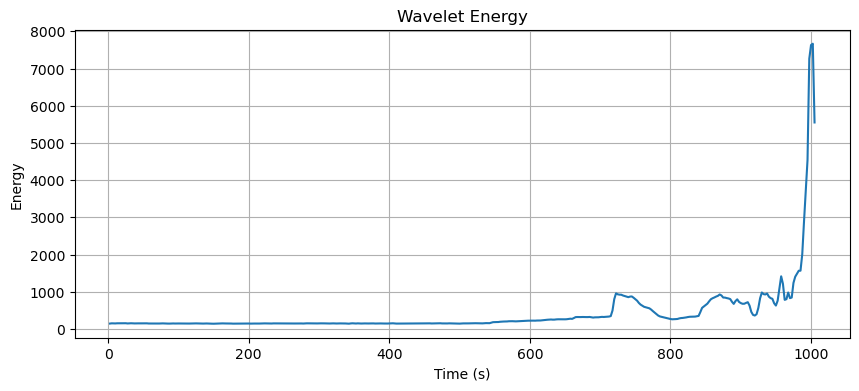

In [36]:
# 1. Wavelet Energy
wavelet_energy = []
for i in range(0, len(vibration) - window_size, step):
    seg    = vibration[i:i+window_size]
    coeffs = wavelet_decompose(seg)
    energy = sum(np.sum(c**2) for c in coeffs)
    wavelet_energy.append(energy)
wavelet_energy = np.array(wavelet_energy)
tf_features["WaveletEnergy"] = wavelet_energy

plt.figure(figsize=(10,4))
plt.plot(time_final, wavelet_energy)
plt.title("Wavelet Energy")
plt.xlabel("Time (s)"); plt.ylabel("Energy")
plt.grid(True)
plt.show()

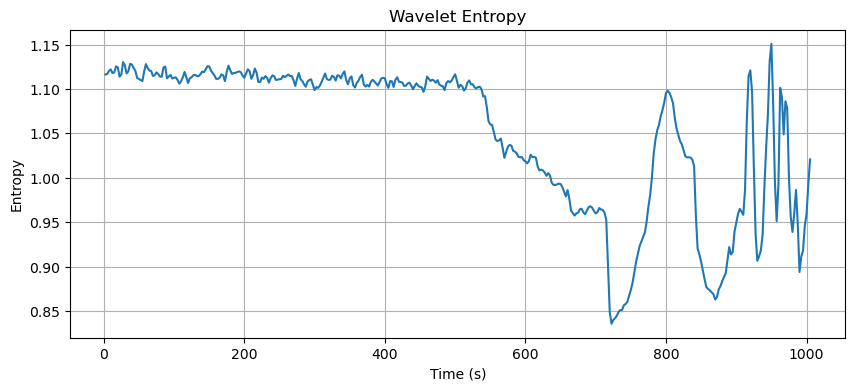

In [37]:
# 2. Wavelet Entropy
wavelet_entropy = []
for i in range(0, len(vibration) - window_size, step):
    seg      = vibration[i:i+window_size]
    coeffs   = wavelet_decompose(seg)
    energies = np.array([np.sum(c**2) for c in coeffs])
    prob     = energies / (np.sum(energies) + 1e-12)
    entropy  = -np.sum(prob * np.log(prob + 1e-12))
    wavelet_entropy.append(entropy)
wavelet_entropy = np.array(wavelet_entropy)
tf_features["WaveletEntropy"] = wavelet_entropy

plt.figure(figsize=(10,4))
plt.plot(time_final, wavelet_entropy)
plt.title("Wavelet Entropy")
plt.xlabel("Time (s)"); plt.ylabel("Entropy")
plt.grid(True)
plt.show()

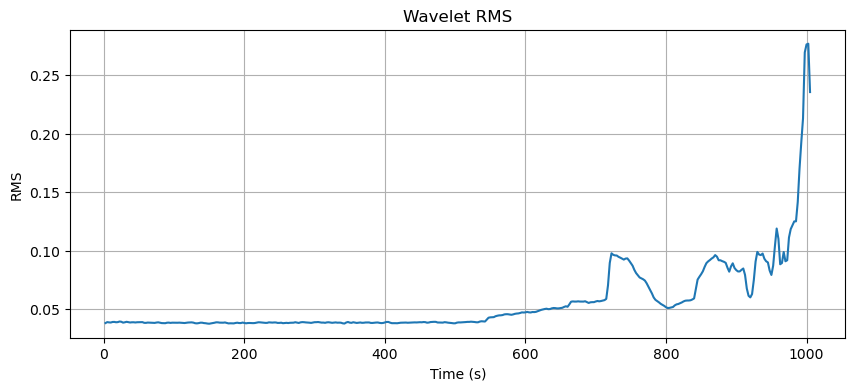

In [38]:
# 3. Wavelet RMS
wavelet_rms = []
for i in range(0, len(vibration) - window_size, step):
    seg      = vibration[i:i+window_size]
    coeffs   = wavelet_decompose(seg)
    combined = np.concatenate(coeffs)
    wavelet_rms.append(np.sqrt(np.mean(combined**2)))
wavelet_rms = np.array(wavelet_rms)
tf_features["WaveletRMS"] = wavelet_rms

plt.figure(figsize=(10,4))
plt.plot(time_final, wavelet_rms)
plt.title("Wavelet RMS")
plt.xlabel("Time (s)"); plt.ylabel("RMS")
plt.grid(True)
plt.show()

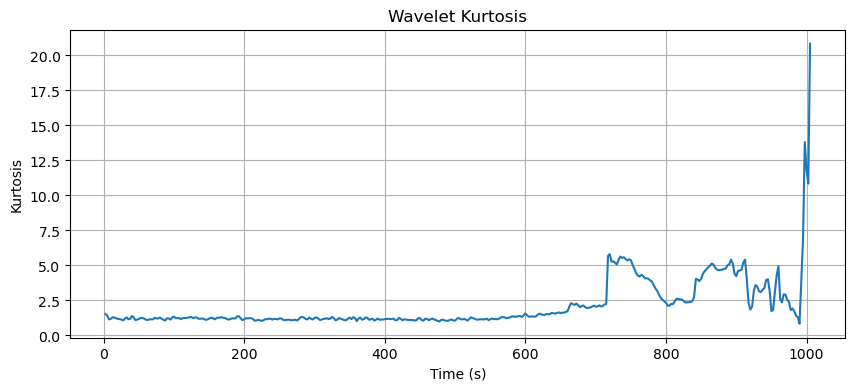

In [39]:
# 4. Wavelet Kurtosis
wavelet_kurt = []
for i in range(0, len(vibration) - window_size, step):
    seg      = vibration[i:i+window_size]
    coeffs   = wavelet_decompose(seg)
    combined = np.concatenate(coeffs)
    wavelet_kurt.append(kurtosis(combined))
wavelet_kurt = np.array(wavelet_kurt)
tf_features["WaveletKurtosis"] = wavelet_kurt

plt.figure(figsize=(10,4))
plt.plot(time_final, wavelet_kurt)
plt.title("Wavelet Kurtosis")
plt.xlabel("Time (s)"); plt.ylabel("Kurtosis")
plt.grid(True)
plt.show()

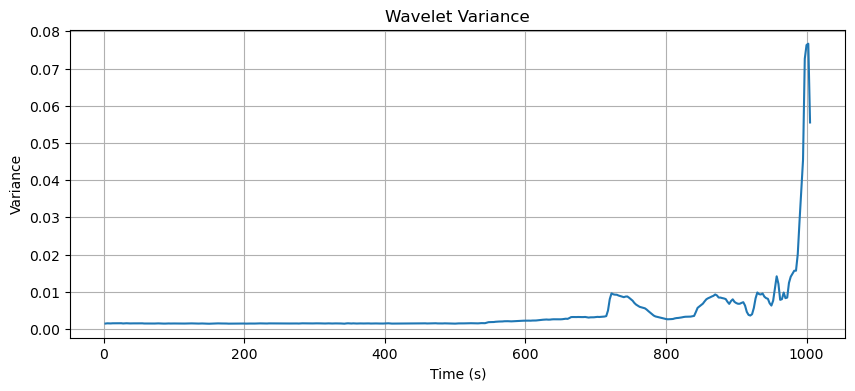

In [40]:
# 5. Wavelet Variance
wavelet_var = []
for i in range(0, len(vibration) - window_size, step):
    seg      = vibration[i:i+window_size]
    coeffs   = wavelet_decompose(seg)
    combined = np.concatenate(coeffs)
    wavelet_var.append(np.var(combined))
wavelet_var = np.array(wavelet_var)
tf_features["WaveletVariance"] = wavelet_var

plt.figure(figsize=(10,4))
plt.plot(time_final, wavelet_var)
plt.title("Wavelet Variance")
plt.xlabel("Time (s)"); plt.ylabel("Variance")
plt.grid(True)
plt.show()

In [41]:
# Build time-frequency DataFrame
tf_df = pd.DataFrame(tf_features)
tf_df["time"] = time_final
print("Time-Frequency features shape:", tf_df.shape)
tf_df.head()

Time-Frequency features shape: (402, 6)


,WaveletEnergy,WaveletEntropy,WaveletRMS,WaveletKurtosis,WaveletVariance,time
0,146.820502,1.116265,0.038317,1.536056,0.001468,2.5
1,153.083439,1.116831,0.039126,1.400458,0.001531,5.0
2,151.132040,1.120375,0.038876,1.149032,0.001511,7.5
3,150.268224,1.122008,0.038764,1.181460,0.001503,10.0
4,153.914199,1.117813,0.039232,1.290564,0.001539,12.5


## Step 4: Combine All Features into One DataFrame

In [42]:
# Combine all three feature sets
final_df = pd.concat([
    time_df.drop(columns=["time"]),
    freq_df.drop(columns=["time"]),
    tf_df
], axis=1)

print("Final feature matrix shape:", final_df.shape)
print("Columns:", list(final_df.columns))
final_df.head()

Final feature matrix shape: (402, 28)
Columns: ['RMS', 'Mean', 'Std', 'Variance', 'Skewness', 'Kurtosis', 'Peak', 'Peak2Peak', 'CrestFactor', 'MAV', 'ShapeFactor', 'ClearanceFactor', 'SpectralEntropy', 'SpectralKurtosis', 'SpectralSkewness', 'PeakFreq', 'SpectralRMS', 'SpectralCentroid', 'SpectralEnergy', 'FreqVariance', 'BandPower1X', 'BandPower2X', 'WaveletEnergy', 'WaveletEntropy', 'WaveletRMS', 'WaveletKurtosis', 'WaveletVariance', 'time']


,RMS,Mean,Std,Variance,Skewness,Kurtosis,Peak,Peak2Peak,CrestFactor,MAV,...,SpectralEnergy,FreqVariance,BandPower1X,BandPower2X,WaveletEnergy,WaveletEntropy,WaveletRMS,WaveletKurtosis,WaveletVariance,time
0,0.076604,-0.004030,0.076497,0.005852,0.051467,0.733794,0.608,1.184,7.936974,0.060066,...,2.942166e+07,4.490723e+06,113318.397315,163464.944952,146.820502,1.116265,0.038317,1.536056,0.001468,2.5
1,0.078190,-0.002040,0.078163,0.006110,0.038836,0.629359,0.608,1.184,7.775928,0.061425,...,3.058917e+07,4.334322e+06,153057.224203,135408.240295,153.083439,1.116831,0.039126,1.400458,0.001531,5.0
2,0.077893,-0.001867,0.077871,0.006064,0.044530,0.446463,0.439,0.847,5.635931,0.061364,...,3.035409e+07,4.289766e+06,153952.608917,141407.397744,151.132040,1.120375,0.038876,1.149032,0.001511,7.5
3,0.077839,-0.001838,0.077817,0.006056,0.031762,0.466530,0.474,0.913,6.089490,0.061285,...,3.031146e+07,4.205768e+06,178887.550000,173396.710946,150.268224,1.122008,0.038764,1.181460,0.001503,10.0
4,0.078591,-0.001731,0.078572,0.006174,0.025385,0.512199,0.474,0.913,6.031211,0.061795,...,3.089777e+07,4.151410e+06,195526.132659,198490.807442,153.914199,1.117813,0.039232,1.290564,0.001539,12.5


## Step 5: Split into Healthy (Train) and Full (Test)

- First 40% of windows = **Healthy** (used to train PCA model)
- All windows = **Test** (used to detect fault and track degradation)

In [43]:
n_total   = len(final_df)
n_healthy = int(0.40 * n_total)   

X_all   = final_df.drop(columns=["time"])
X_train = X_all.iloc[:n_healthy]  
X_test  = X_all              

print("Total windows  :", n_total)
print("Healthy (train):", n_healthy)
print("Test (all)     :", len(X_test))

Total windows  : 402
Healthy (train): 160
Test (all)     : 402


## Step 6: Normalize Features

In [44]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled  = scaler.transform(X_test)
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled  = pd.DataFrame(X_test_scaled,  columns=X_test.columns)

print("Train scaled shape:", X_train_scaled.shape)
print("Test  scaled shape:", X_test_scaled.shape)
X_train_scaled.head()

Train scaled shape: (160, 27)
Test  scaled shape: (402, 27)


,RMS,Mean,Std,Variance,Skewness,Kurtosis,Peak,Peak2Peak,CrestFactor,MAV,...,SpectralCentroid,SpectralEnergy,FreqVariance,BandPower1X,BandPower2X,WaveletEnergy,WaveletEntropy,WaveletRMS,WaveletKurtosis,WaveletVariance
0,0.207134,0.000000,0.182768,0.179571,1.000000,1.000000,1.000000,1.000000,1.000000,0.092602,...,0.669895,0.227681,1.000000,0.000000,0.673550,0.298220,0.558066,0.303355,1.000000,0.297872
1,0.685012,0.810691,0.684457,0.679833,0.867420,0.735701,1.000000,1.000000,0.942320,0.630441,...,0.718716,0.680963,0.689457,0.115551,0.439093,0.728839,0.576145,0.733587,0.736444,0.728951
2,0.595571,0.881051,0.596311,0.591157,0.927188,0.272839,0.202830,0.184019,0.175862,0.606401,...,0.473380,0.589693,0.600989,0.118154,0.489225,0.594667,0.689326,0.600495,0.247756,0.594679
3,0.579292,0.893235,0.580245,0.575030,0.793177,0.323624,0.367925,0.343826,0.338308,0.574981,...,0.313066,0.573141,0.434205,0.190659,0.756545,0.535274,0.741466,0.541306,0.310785,0.535210
4,0.805846,0.936844,0.807541,0.804213,0.726236,0.439201,0.367925,0.343826,0.317435,0.777107,...,0.471789,0.800773,0.326276,0.239040,0.966245,0.785959,0.607501,0.789989,0.522847,0.786145


## Step 7: PCA — Dimensionality Reduction

PCA is trained on healthy data only.
It learns the **normal pattern** of the bearing.
When the bearing degrades, data deviates from this pattern.

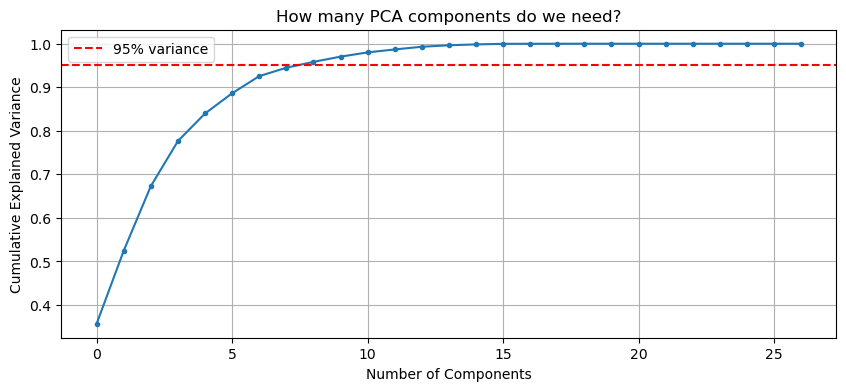

In [45]:
from sklearn.decomposition import PCA
pca_full = PCA()
pca_full.fit(X_train_scaled)

plt.figure(figsize=(10,4))
plt.plot(pca_full.explained_variance_ratio_.cumsum(), marker='o', markersize=3)
plt.axhline(0.95, color='red', linestyle='--', label='95% variance')
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("How many PCA components do we need?")
plt.legend()
plt.grid(True)
plt.show()

In [46]:
n_components = 8

pca = PCA(n_components=n_components)
pca.fit(X_train_scaled) 

for i, var in enumerate(pca.explained_variance_ratio_):
    print(f"PC{i+1} explains {var*100:.2f}% variance")
print(f"\nTotal: {pca.explained_variance_ratio_.sum()*100:.2f}%")

PC1 explains 35.71% variance
PC2 explains 16.77% variance
PC3 explains 14.82% variance
PC4 explains 10.35% variance
PC5 explains 6.34% variance
PC6 explains 4.64% variance
PC7 explains 3.94% variance
PC8 explains 1.93% variance

Total: 94.49%


## Step 8: PCA Score Matrix

Project all data (train + test) onto the PCA components.
This gives us the **PC scores** for each window — a new table with fewer columns.

In [47]:
pca = PCA(n_components=8)

pca.fit(X_train_scaled)

scores_train = pca.transform(X_train_scaled)
scores_test = pca.transform(X_test_scaled)

print(scores_test.shape)


(402, 8)


In [48]:
scores_all = pca.transform(X_test_scaled)
score_cols = [f"PC{i+1}" for i in range(n_components)]
pca_df     = pd.DataFrame(scores_all, columns=score_cols)
pca_df["time"] = time_final[:len(pca_df)]

print("PCA Score Matrix shape:", pca_df.shape)
print("\nSample (first 5 rows):")
print(pca_df.head())

PCA Score Matrix shape: (402, 9)

Sample (first 5 rows):
        PC1       PC2       PC3       PC4       PC5       PC6       PC7  \
0 -0.286477  2.035153  1.046428 -0.254001  0.615973  0.216733  0.118864   
1  0.968799  1.396403  0.948631 -0.251547  0.071437 -0.030383  0.275917   
2  0.586179  0.398413 -0.236731  0.426466  0.368338 -0.473142  0.274984   
3  0.551897  0.728401 -0.335823  0.229161  0.172755 -0.338859  0.269033   
4  1.288762  0.565280 -0.096836  0.072188  0.333420 -0.200150  0.307108   

        PC8  time  
0  0.441532   2.5  
1 -0.097224   5.0  
2  0.100616   7.5  
3  0.131146  10.0  
4  0.189398  12.5  


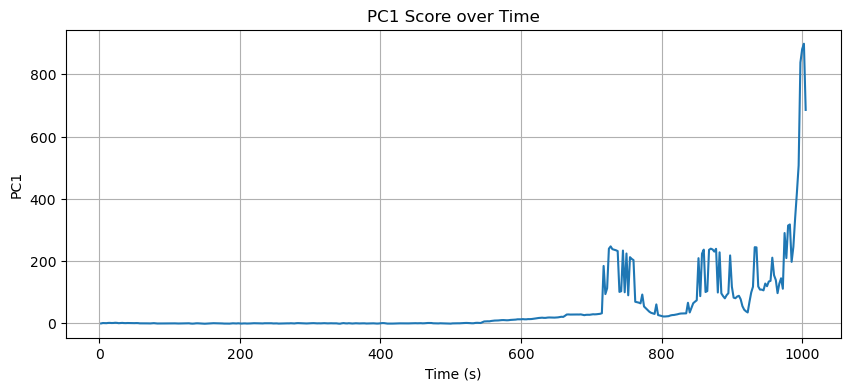

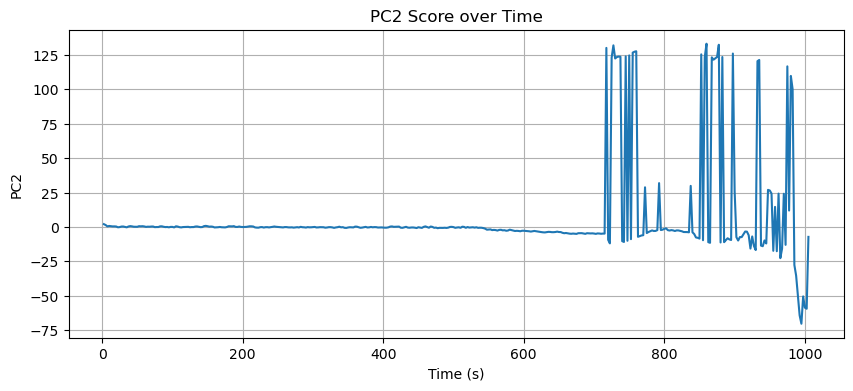

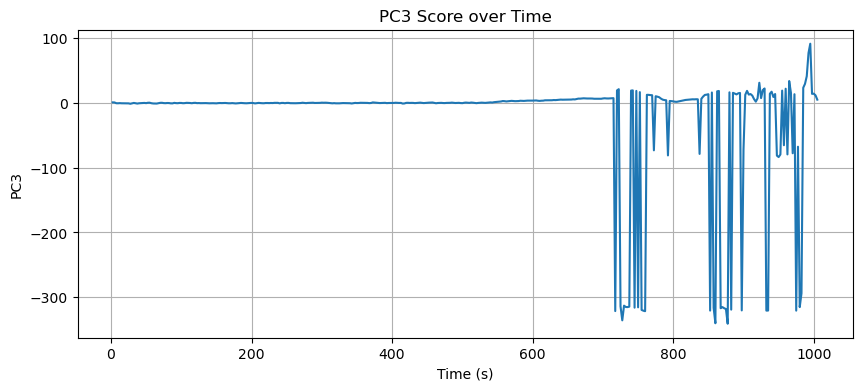

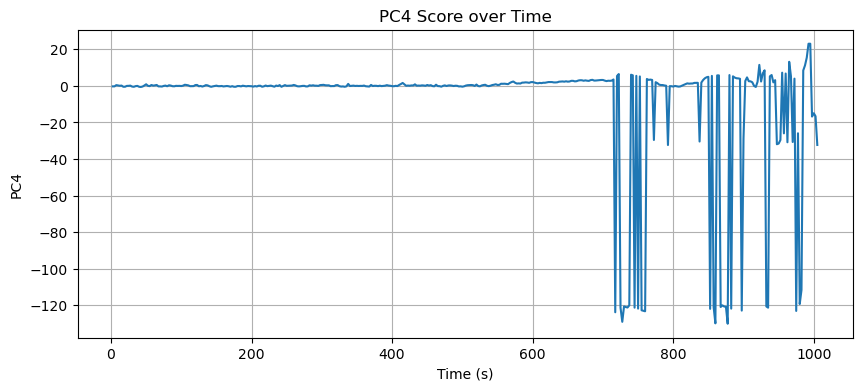

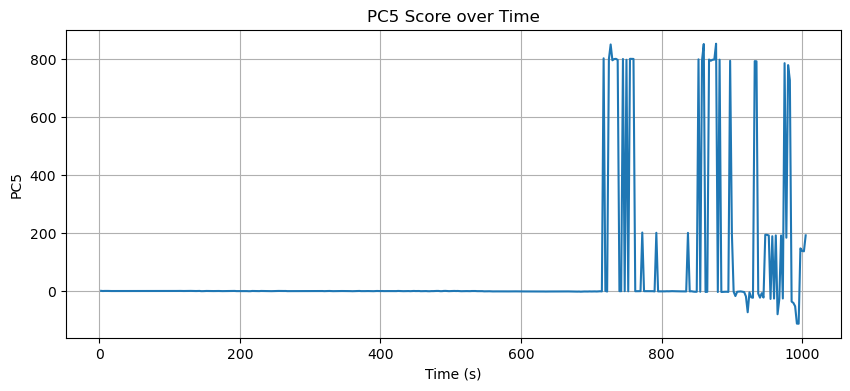

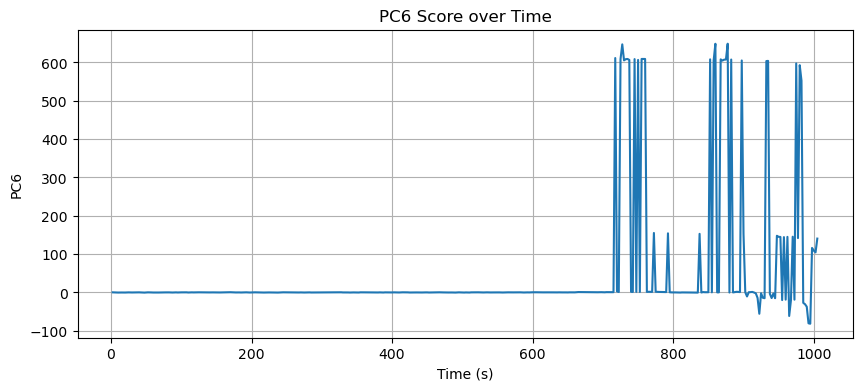

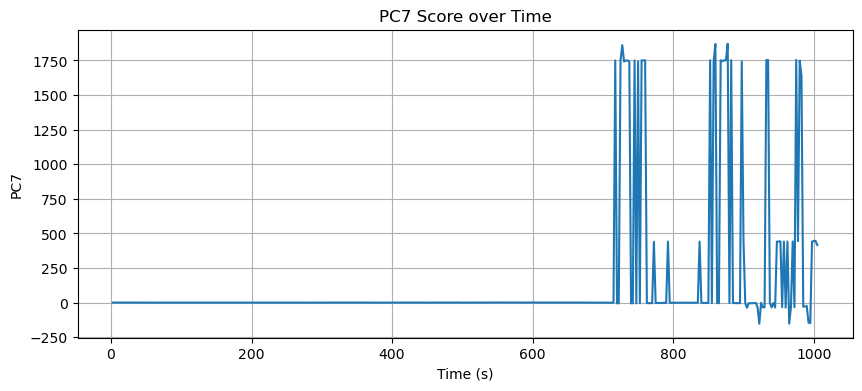

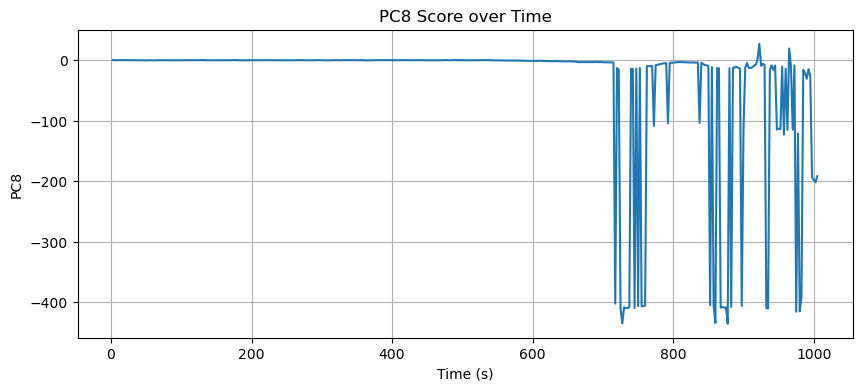

In [49]:
# Plot each PC score over time
for col in score_cols:
    plt.figure(figsize=(10,4))
    plt.plot(pca_df["time"], pca_df[col])
    plt.title(f"{col} Score over Time")
    plt.xlabel("Time (s)")
    plt.ylabel(col)
    plt.grid(True)
    plt.show()

## Step 9: Feature Fusion — Global PC (GPC)

We combine all PC scores into one single value.
Each PC gets a weight based on how much variance it explains.

**GPC = w1×PC1 + w2×PC2 + w3×PC3 + ...**

This gives one trend that represents overall bearing degradation.

Fusion weights:
  PC1: 0.3571
  PC2: 0.1677
  PC3: 0.1482
  PC4: 0.1035
  PC5: 0.0634
  PC6: 0.0464
  PC7: 0.0394
  PC8: 0.0193


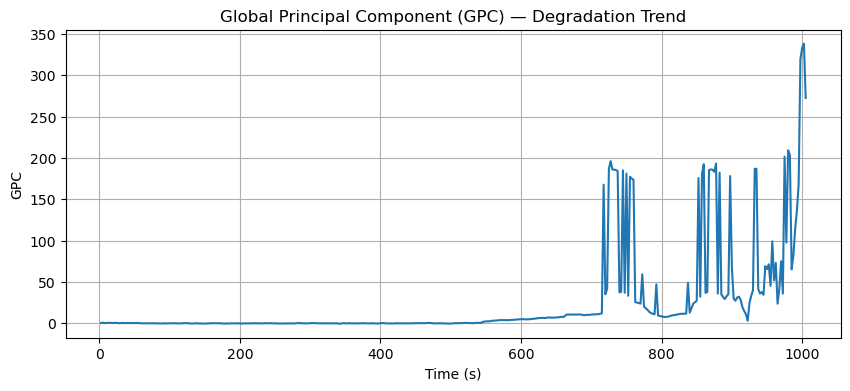

In [50]:
weights = pca.explained_variance_ratio_

print("Fusion weights:")
for i, w in enumerate(weights):
    print(f"  PC{i+1}: {w:.4f}")
GPC = scores_all @ weights 

plt.figure(figsize=(10,4))
plt.plot(time_final, GPC)
plt.title("Global Principal Component (GPC) — Degradation Trend")
plt.xlabel("Time (s)")
plt.ylabel("GPC")
plt.grid(True)
plt.show()

## Step 10: Health Indicator (HI)

We normalize GPC to get a **Health Indicator** between 0 and 1.
- HI ≈ 0 → bearing is healthy
- HI increases → bearing is degrading
- HI → 1 → bearing is near failure

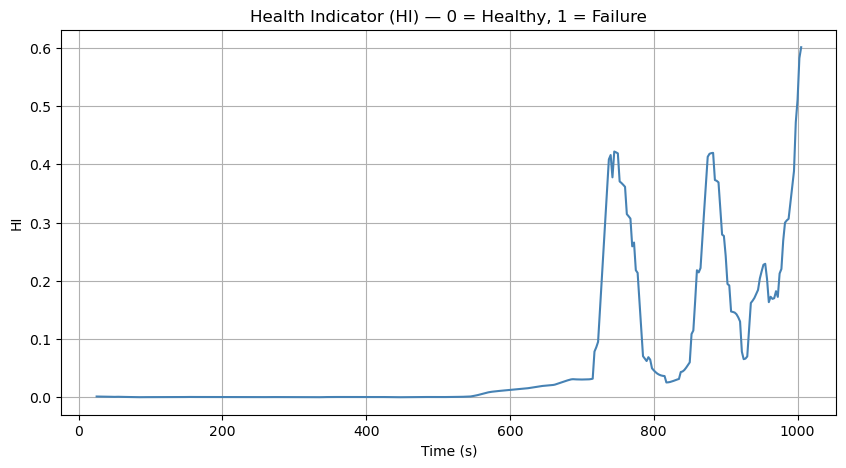

In [51]:
# Take absolute value then normalize to [0, 1]
HI_raw = np.abs(GPC)
HI_min = HI_raw.min()
HI_max = HI_raw.max()
HI = (HI_raw - HI_min) / (HI_max - HI_min + 1e-12)
HI_smooth = pd.Series(HI).rolling(10).mean()


plt.figure(figsize=(10,5))
plt.plot(time_final, HI_smooth, color='steelblue')
plt.title("Health Indicator (HI) — 0 = Healthy, 1 = Failure")
plt.xlabel("Time (s)")
plt.ylabel("HI")
plt.grid(True)
plt.show()

## Step 12: Threshold and Anomaly Detection

We compute the threshold from the **healthy training data**:

**Threshold = mean + 3 × std**

When HI crosses this threshold → **fault detected**.

Threshold (mean + 3σ): 0.0017


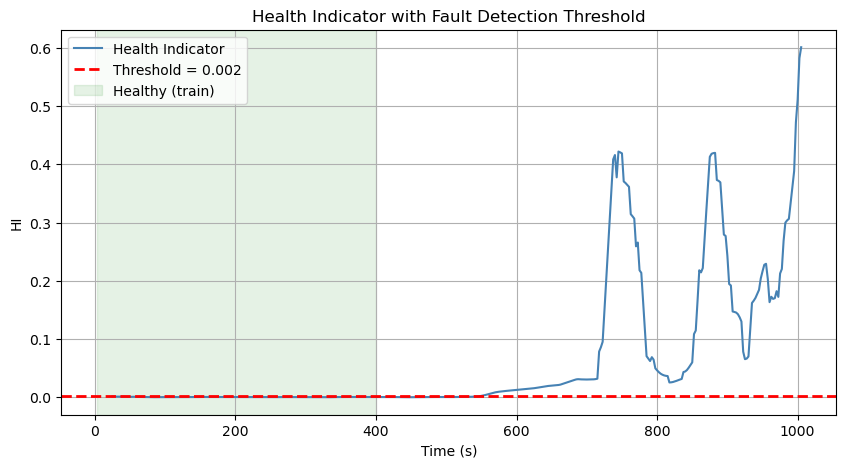

In [52]:
# Healthy portion of HI
HI_healthy = HI[:n_healthy]

threshold = np.mean(HI_healthy) + 3 * np.std(HI_healthy)
print("Threshold (mean + 3σ):", round(threshold, 4))

plt.figure(figsize=(10,5))
plt.plot(time_final, HI_smooth, color='steelblue', label='Health Indicator')
plt.axhline(threshold, color='red', linestyle='--', linewidth=2, label=f'Threshold = {threshold:.3f}')
plt.axvspan(time_final[0], time_final[n_healthy-1], alpha=0.1, color='green', label='Healthy (train)')
plt.title("Health Indicator with Fault Detection Threshold")
plt.xlabel("Time (s)")
plt.ylabel("HI")
plt.legend()
plt.grid(True)
plt.show()

## Step 13: Fault Diagnosis — Find Fault Onset Time

In [53]:
fault_indices = np.where(HI > threshold)[0][0]
fault_time = time_final[fault_indices]
print("Fault starts at:", round(fault_time,2), "seconds")

Fault starts at: 5.0 seconds


In [54]:
# search only after healthy region
fault_indices = np.where(HI[n_healthy:] > threshold)[0]

if len(fault_indices) > 0:
    fault_onset_idx = fault_indices[0] + n_healthy
    fault_onset_time = time_final[fault_onset_idx]

    print(f"⚠ Fault detected at time = {fault_onset_time:.2f} seconds")
    print(f"Window index = {fault_onset_idx}")
    print(f"HI value at onset = {HI[fault_onset_idx]:.4f}")
else:
    print("No fault detected")


⚠ Fault detected at time = 537.50 seconds
Window index = 214
HI value at onset = 0.0018


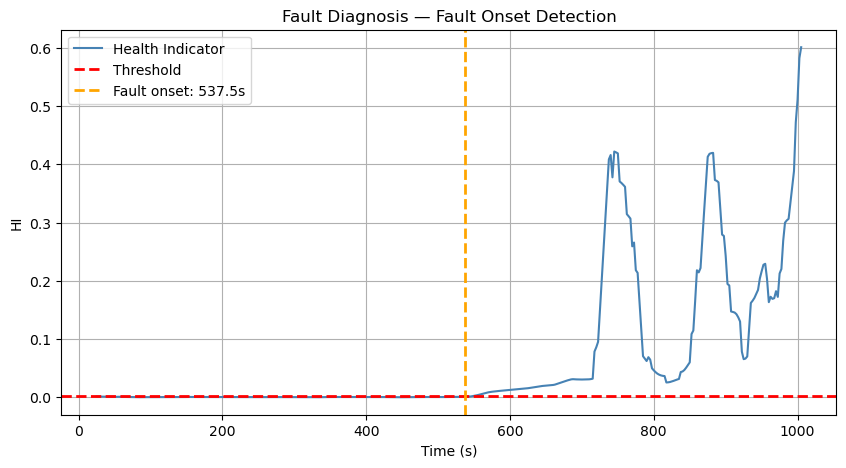

In [55]:
plt.figure(figsize=(10,5))
plt.plot(time_final, HI_smooth, color='steelblue', label='Health Indicator')
plt.axhline(threshold, color='red', linestyle='--', linewidth=2, label='Threshold')
plt.axvline(fault_onset_time, color='orange', linestyle='--', linewidth=2,
            label=f'Fault onset: {fault_onset_time:.1f}s')
plt.title("Fault Diagnosis — Fault Onset Detection")
plt.xlabel("Time (s)")
plt.ylabel("HI")
plt.legend()
plt.grid(True)
plt.show()

In [56]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Combine useful features
X_cluster = np.column_stack([
    HI,
    scores_all[:,0],
    scores_all[:,1]
])


In [57]:
valid_idx = ~np.isnan(X_cluster).any(axis=1)
X_cluster_clean = X_cluster[valid_idx]

In [58]:
kmeans = KMeans(n_clusters=3, random_state=42)

clusters = kmeans.fit_predict(X_cluster_clean)
clusters_full = np.full(len(HI_smooth), -1) 

clusters_full[valid_idx] = clusters
pca_df["cluster"] = clusters_full


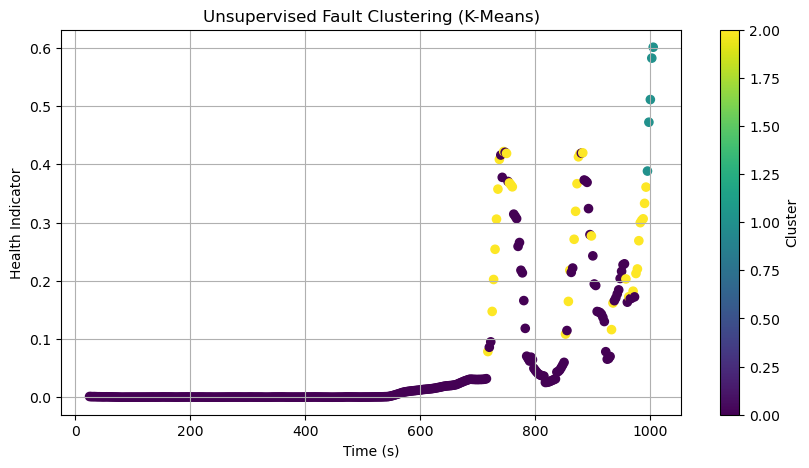

In [59]:
plt.figure(figsize=(10,5))

plt.scatter(time_final, HI_smooth,
            c=pca_df["cluster"],
            cmap="viridis",
            s=35)

plt.xlabel("Time (s)")
plt.ylabel("Health Indicator")
plt.title("Unsupervised Fault Clustering (K-Means)")
plt.colorbar(label="Cluster")

plt.grid(True)
plt.show()



In [195]:
print("Cluster distribution:")
print(pca_df["cluster"].value_counts())


Cluster distribution:
cluster
0    364
2     23
1      5
Name: count, dtype: int64


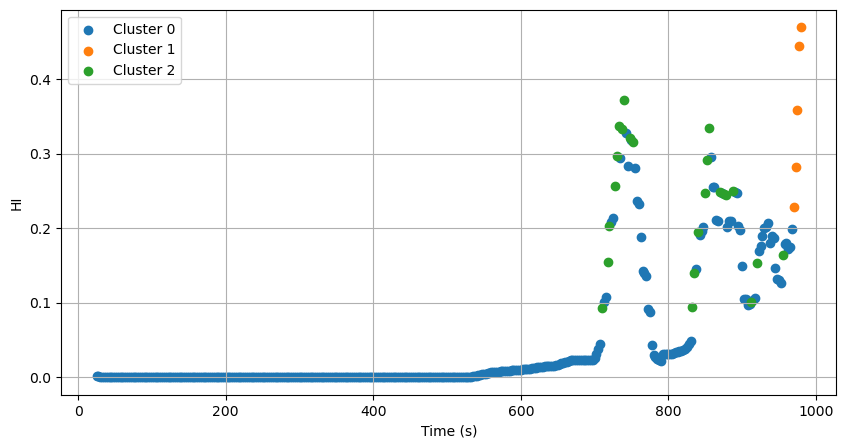

In [201]:
plt.figure(figsize=(10,5))

for c in np.unique(pca_df["cluster"]):
    idx = pca_df["cluster"] == c
    plt.scatter(time_final[idx], HI_smooth[idx], label=f"Cluster {c}")

plt.xlabel("Time (s)")
plt.ylabel("HI")
plt.legend()
plt.grid()
plt.show()


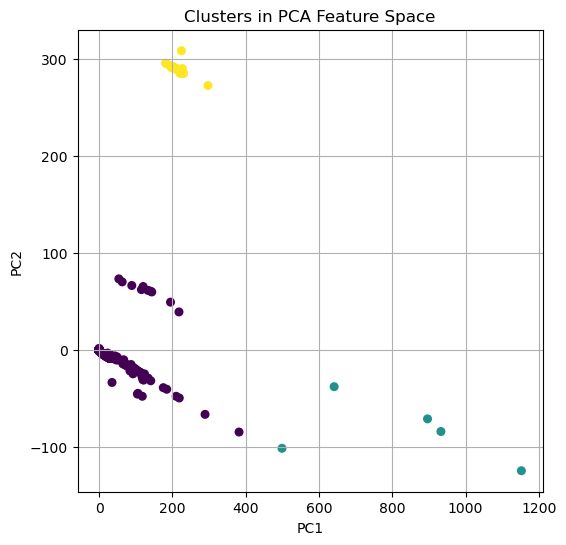

In [196]:
plt.figure(figsize=(6,6))

plt.scatter(scores_all[:,0],
            scores_all[:,1],
            c=pca_df["cluster"],
            cmap="viridis",
            s=30)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Clusters in PCA Feature Space")

plt.grid(True)
plt.show()


## Step 14: Bearing Fault Type Diagnosis using FFT


In [254]:

from scipy.signal import find_peaks


BPFO = 236   # Outer race
BPFI = 296   # Inner race
BSF  = 279   # Ball fault

fault_region = vibration[-window_size:]
N = len(fault_region)
freqs = fftfreq(N, d=1/Fs)[:N//2]
spectrum = np.abs(fft(fault_region))[:N//2]

peaks, _ = find_peaks(spectrum, height=np.max(spectrum)*0.2)
dominant_freqs = freqs[peaks]
print("Dominant Frequencies Detected:")
print(dominant_freqs[:10])

Dominant Frequencies Detected:
[231.  462.2 692.8 693.4 917.2 924.2 924.6 925.  985.  985.4]


In [255]:
# Fault Type Identification
fault_type = "Unknown"

for f in dominant_freqs:
    if abs(f - BPFO) < 20:
        fault_type = "Outer Race Fault"
        break
    elif abs(f - BPFI) < 20:
        fault_type = "Inner Race Fault"
        break
    elif abs(f - BSF) < 20:
        fault_type = "Ball Fault"
        break
print("\nDetected Fault Type:", fault_type)


Detected Fault Type: Outer Race Fault


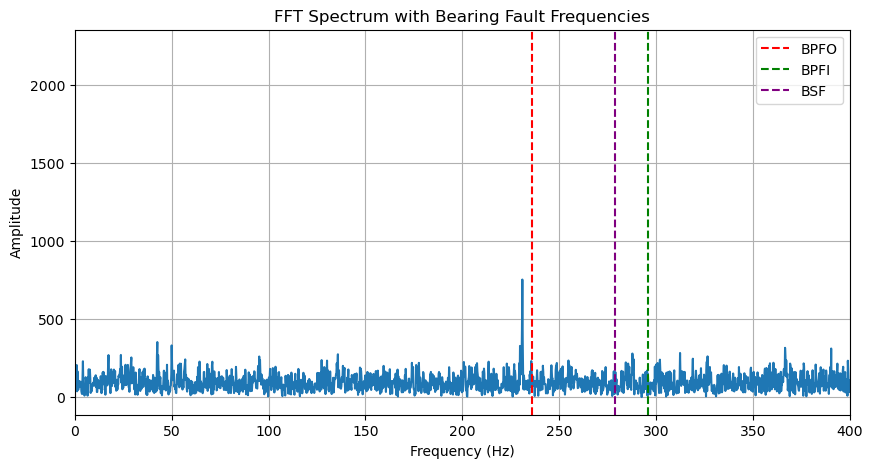

In [256]:

plt.figure(figsize=(10,5))
plt.plot(freqs, spectrum)

plt.axvline(BPFO, color='r', linestyle='--', label='BPFO')
plt.axvline(BPFI, color='g', linestyle='--', label='BPFI')
plt.axvline(BSF,  color='purple', linestyle='--', label='BSF')

plt.xlim(0,400)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("FFT Spectrum with Bearing Fault Frequencies")
plt.legend()
plt.grid()
plt.show()


In [261]:
tolerance = 10 

def get_fault_energy(target_freq):
    idx = np.where((freqs > target_freq - tolerance) & 
                   (freqs < target_freq + tolerance))[0]
    if len(idx) == 0:
        return 0
    
    return np.max(spectrum[idx])


In [258]:
bpfo_amp = get_fault_energy(BPFO)
bpfi_amp = get_fault_energy(BPFI)
bsf_amp  = get_fault_energy(BSF)

print("BPFO amplitude:", bpfo_amp)
print("BPFI amplitude:", bpfi_amp)
print("BSF amplitude:", bsf_amp)


BPFO amplitude: 753.9415781666228
BPFI amplitude: 280.3138253729301
BSF amplitude: 280.3138253729301


In [259]:
fault_dict = {
    "Outer Race Fault": bpfo_amp,
    "Inner Race Fault": bpfi_amp,
    "Ball Fault": bsf_amp
}

fault_type = max(fault_dict, key=fault_dict.get)

print("\nDetected Fault Type:", fault_type)



Detected Fault Type: Outer Race Fault


In [239]:
start_sample = int(fault_onset_idx * step)
end_sample = start_sample + window_size

fault_signal = vibration[start_sample:end_sample]

print("Fault signal length:", len(fault_signal))


Fault signal length: 100000


In [251]:
print("fault_onset_idx:", fault_onset_idx)
print("window_size:", window_size)
print("step:", step)
print("len(vibration):", len(vibration))


fault_onset_idx: 212
window_size: 100000
step: 50000
len(vibration): 20152320


## Step 14: Feature Contribution — Which Features Matter Most?

PCA loadings tell us how much each original feature drives each PC.
We weight each loading by how much variance that PC explains.
The result is a contribution score for every feature.

In [260]:
loadings = pca.components_
contribution = np.sum(
    np.abs(loadings) * pca.explained_variance_ratio_[:, np.newaxis],
    axis=0
)

feature_names = list(X_train.columns)
contrib_df = pd.DataFrame({
    "Feature": feature_names,
    "Contribution": contribution
})
contrib_df = contrib_df.sort_values("Contribution", ascending=False).reset_index(drop=True)

print("Feature Contributions (ranked):")
print(contrib_df.to_string())

Feature Contributions (ranked):
             Feature  Contribution
0        BandPower1X      0.170814
1        BandPower2X      0.161381
2        ShapeFactor      0.161195
3   SpectralCentroid      0.160443
4    SpectralEntropy      0.160128
5     WaveletEntropy      0.152790
6         WaveletRMS      0.150049
7    WaveletVariance      0.149633
8      WaveletEnergy      0.149579
9                MAV      0.147229
10              Peak      0.140039
11               Std      0.134787
12          Variance      0.134313
13          PeakFreq      0.134073
14               RMS      0.133999
15            Energy      0.133539
16       SpectralRMS      0.133212
17    SpectralEnergy      0.132767
18  SpectralSkewness      0.130803
19       CrestFactor      0.130432
20         Peak2Peak      0.126280
21  SpectralKurtosis      0.121597
22   WaveletKurtosis      0.120707
23          Kurtosis      0.118121
24          Skewness      0.101812
25      FreqVariance      0.101417
26              Mean   

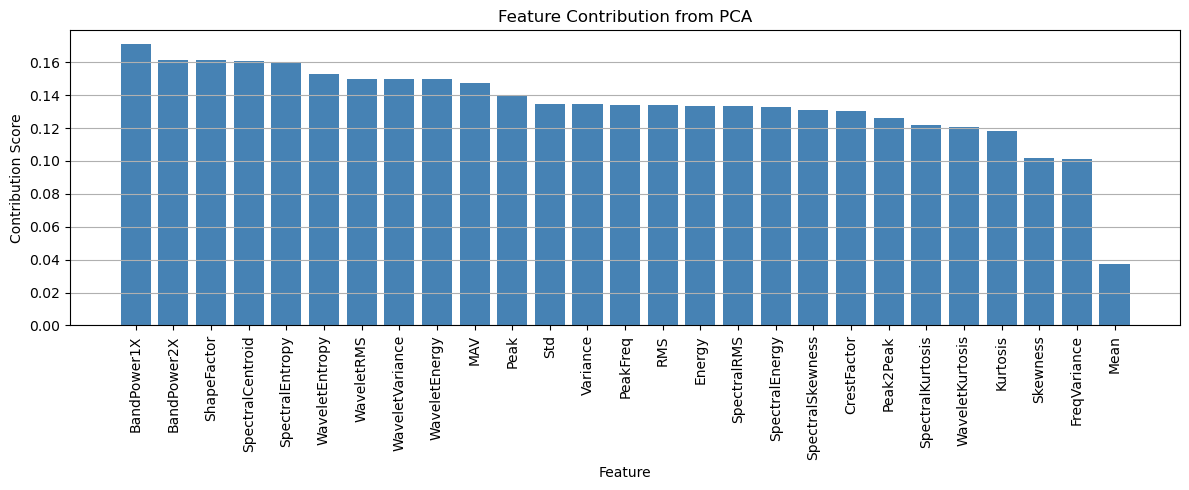

In [53]:
plt.figure(figsize=(12, 5))
plt.bar(contrib_df["Feature"], contrib_df["Contribution"], color="steelblue")
plt.xticks(rotation=90)
plt.title("Feature Contribution from PCA")
plt.ylabel("Contribution Score")
plt.xlabel("Feature")
plt.tight_layout()
plt.grid(axis="y")
plt.show()

## Step 15: Select Top Contributing Features

We keep the top N features.
Change  to use more or fewer features.

In [55]:
top_n = 5   # change this if needed

top_features = contrib_df["Feature"].iloc[:top_n].tolist()

print(f"Top {top_n} features:")
for f in top_features:
    print(" -", f)

X_top_train = X_train_scaled[top_features]
X_top_test  = X_test_scaled[top_features]

print("Train shape:", X_top_train.shape)
print("Test  shape:", X_top_test.shape)

Top 5 features:
 - BandPower1X
 - BandPower2X
 - ShapeFactor
 - SpectralCentroid
 - SpectralEntropy
Train shape: (156, 5)
Test  shape: (392, 5)


## Step 16: Build Health Indicator from Top Features

HI = mean of the top features (already scaled 0–1), then normalized to [0, 1].
This HI is more focused — built only from the most informative features.

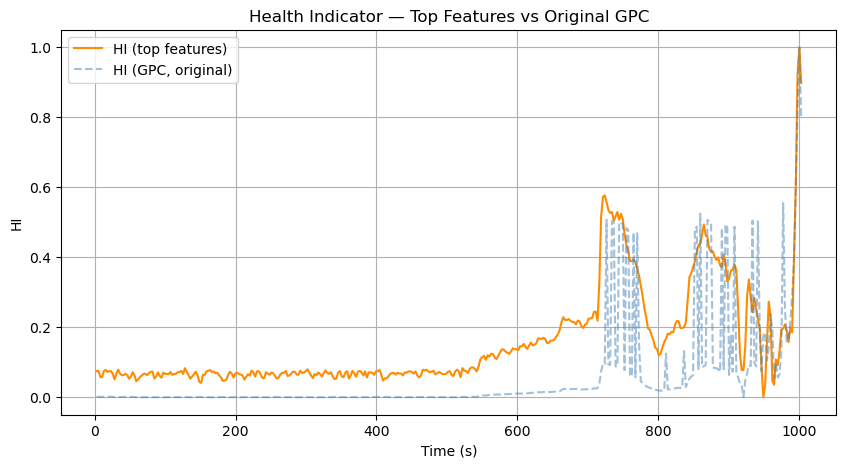

In [56]:
HI_top_raw = X_top_test.mean(axis=1).values

HI_top = (HI_top_raw - HI_top_raw.min()) / (HI_top_raw.max() - HI_top_raw.min() + 1e-12)

plt.figure(figsize=(10, 5))
plt.plot(time_final, HI_top, color="darkorange", label="HI (top features)")
plt.plot(time_final, HI,     color="steelblue",  linestyle="--", alpha=0.5, label="HI (GPC, original)")
plt.title("Health Indicator — Top Features vs Original GPC")
plt.xlabel("Time (s)")
plt.ylabel("HI")
plt.legend()
plt.grid(True)
plt.show()

Threshold (top features): 0.0896
Fault onset: 547.84s


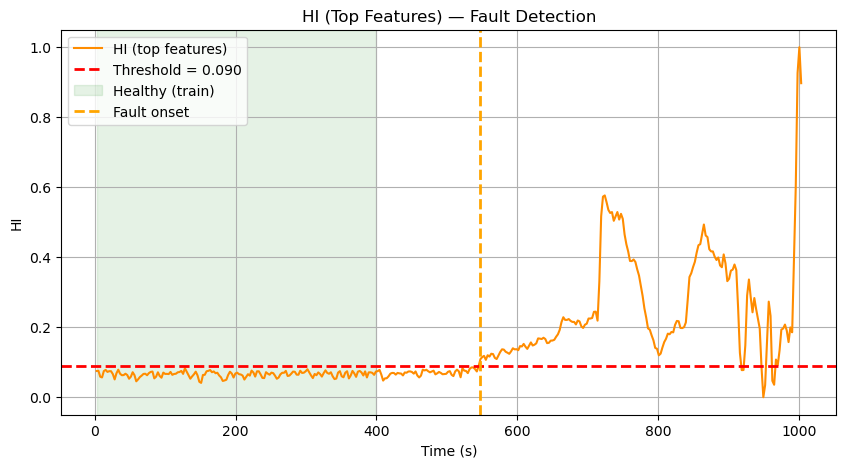

In [57]:
# Threshold from healthy portion of new HI
HI_top_healthy  = HI_top[:n_healthy]
threshold_top   = np.mean(HI_top_healthy) + 3 * np.std(HI_top_healthy)

print("Threshold (top features):", round(threshold_top, 4))

fault_idx_top = np.where(HI_top > threshold_top)[0]
if len(fault_idx_top) > 0:
    fault_onset_idx_top  = fault_idx_top[0]
    fault_onset_time_top = time_final[fault_onset_idx_top]
    print(f"Fault onset: {fault_onset_time_top:.2f}s")
else:
    fault_onset_idx_top  = len(time_final) - 1
    fault_onset_time_top = time_final[-1]
    print("No fault detected.")

plt.figure(figsize=(10, 5))
plt.plot(time_final, HI_top, color="darkorange", label="HI (top features)")
plt.axhline(threshold_top, color="red", linestyle="--", linewidth=2,
            label=f"Threshold = {threshold_top:.3f}")
plt.axvspan(time_final[0], time_final[n_healthy-1],
            alpha=0.1, color="green", label="Healthy (train)")
plt.axvline(fault_onset_time_top, color="orange", linestyle="--",
            linewidth=2, label="Fault onset")
plt.title("HI (Top Features) — Fault Detection")
plt.xlabel("Time (s)")
plt.ylabel("HI")
plt.legend()
plt.grid(True)
plt.show()

## Step 17: RUL Prediction using Regression

We use **RandomForestRegressor** to predict RUL.

- **Input (X):** top features at each window
- **Target (y):** RUL = time remaining until failure

Train on the healthy portion, test on all data.

Failure time: 998.40s


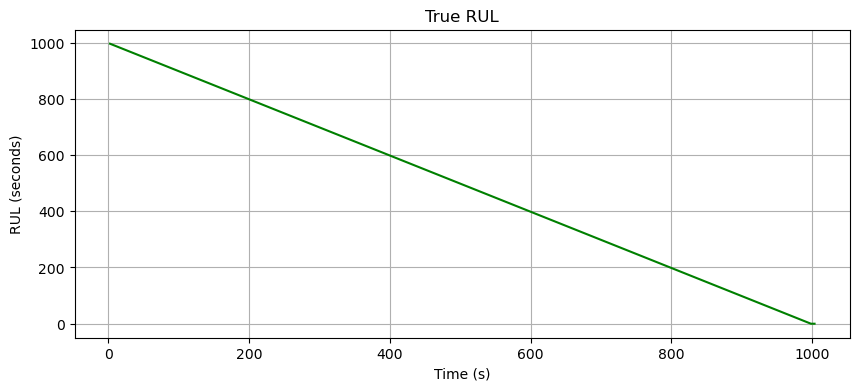

In [58]:
# Define failure = when HI_top first hits 0.85
HI_FAILURE = 0.85

fail_indices = np.where(HI_top >= HI_FAILURE)[0]
if len(fail_indices) > 0:
    failure_time_top = time_final[fail_indices[0]]
else:
    failure_time_top = time_final[-1]

print(f"Failure time: {failure_time_top:.2f}s")

RUL_true = np.maximum(failure_time_top - time_final, 0)

plt.figure(figsize=(10, 4))
plt.plot(time_final, RUL_true, color="green")
plt.title("True RUL")
plt.xlabel("Time (s)")
plt.ylabel("RUL (seconds)")
plt.grid(True)
plt.show()

In [59]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

X_reg = X_top_test.values
y_reg = RUL_true

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

model = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
model.fit(X_train_reg, y_train_reg)

print("Model trained!")
print("Train size:", len(X_train_reg))
print("Test  size:", len(X_test_reg))

Model trained!
Train size: 313
Test  size: 79


In [60]:
preds = model.predict(X_test_reg)

MAE  = mean_absolute_error(y_test_reg, preds)
RMSE = np.sqrt(mean_squared_error(y_test_reg, preds))

print("RUL Prediction Results:")
print(f"  MAE  = {MAE:.2f} seconds")
print(f"  RMSE = {RMSE:.2f} seconds")

RUL Prediction Results:
  MAE  = 72.27 seconds
  RMSE = 111.04 seconds


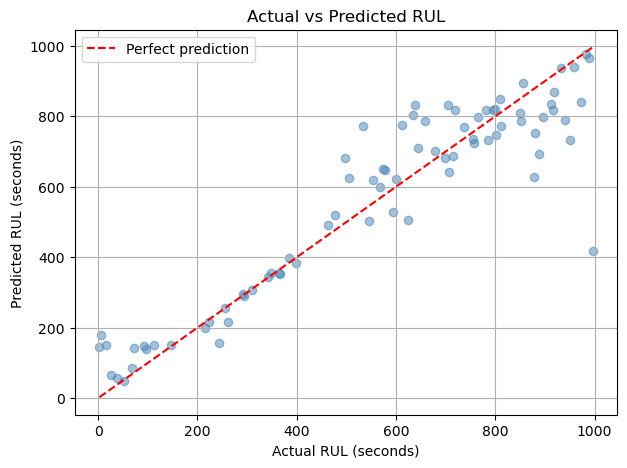

In [61]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test_reg, preds, alpha=0.5, color="steelblue")
plt.plot([y_test_reg.min(), y_test_reg.max()],
         [y_test_reg.min(), y_test_reg.max()],
         color="red", linestyle="--", label="Perfect prediction")
plt.xlabel("Actual RUL (seconds)")
plt.ylabel("Predicted RUL (seconds)")
plt.title("Actual vs Predicted RUL")
plt.legend()
plt.grid(True)
plt.show()

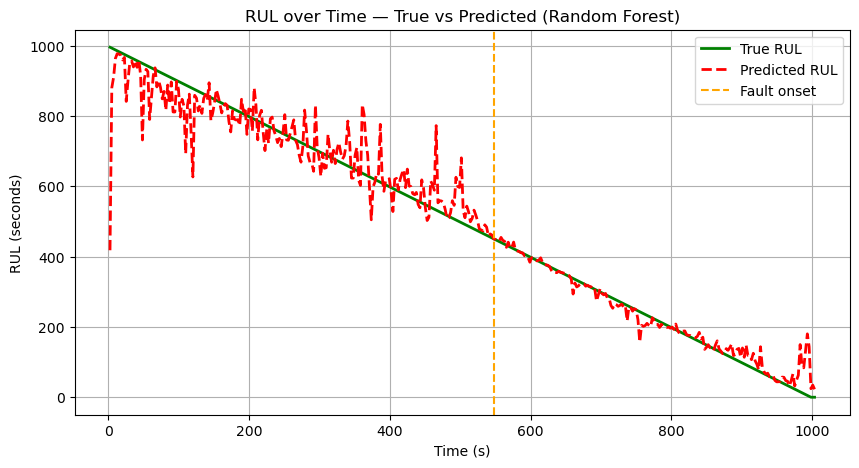

In [62]:
# Predict RUL for all windows in time order
RUL_pred_all = model.predict(X_reg)

plt.figure(figsize=(10, 5))
plt.plot(time_final, RUL_true,     color="green", linewidth=2, label="True RUL")
plt.plot(time_final, RUL_pred_all, color="red",   linewidth=2, linestyle="--", label="Predicted RUL")
plt.axvline(fault_onset_time_top, color="orange", linestyle="--", linewidth=1.5, label="Fault onset")
plt.title("RUL over Time — True vs Predicted (Random Forest)")
plt.xlabel("Time (s)")
plt.ylabel("RUL (seconds)")
plt.legend()
plt.grid(True)
plt.show()

## Final Summary Plot

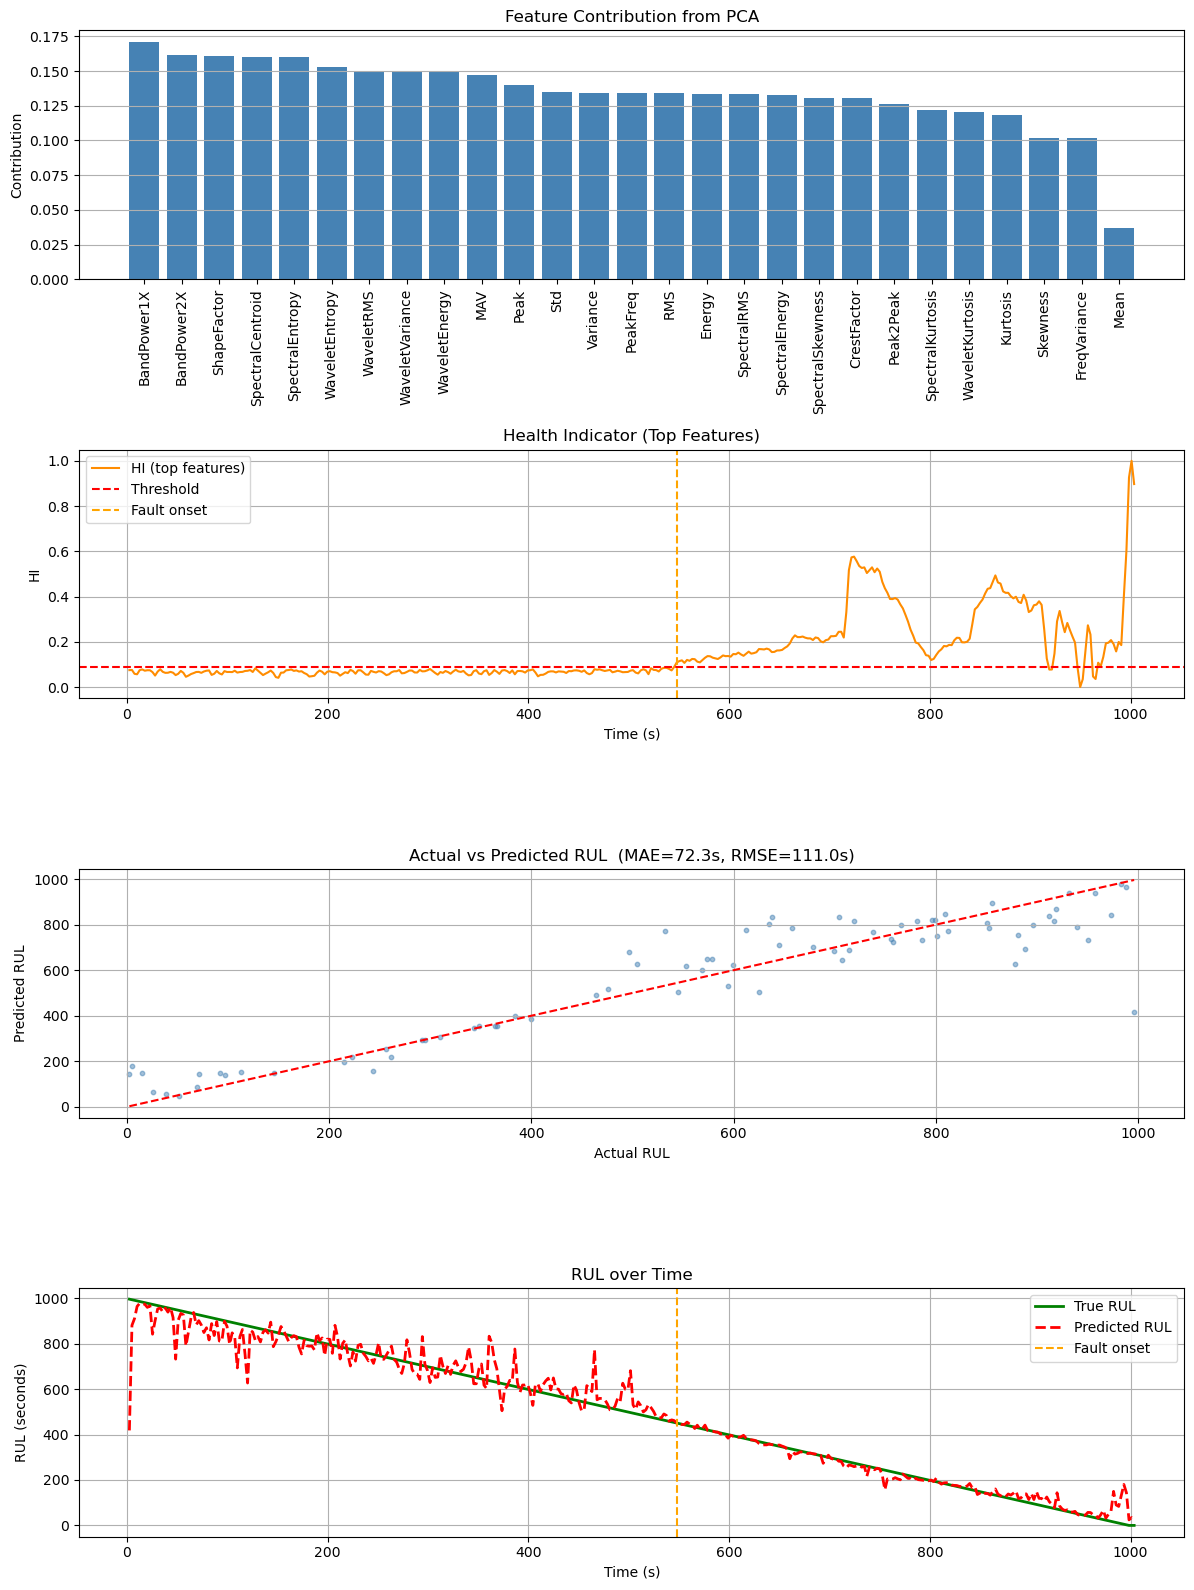

✅ RUL Prediction project complete!


In [64]:
fig, axes = plt.subplots(4, 1, figsize=(12, 16))

# 1. Feature Contribution
axes[0].bar(contrib_df["Feature"], contrib_df["Contribution"], color="steelblue")
axes[0].set_title("Feature Contribution from PCA")
axes[0].set_ylabel("Contribution")
axes[0].tick_params(axis="x", rotation=90)
axes[0].grid(axis="y")

# 2. Health Indicator (top features)
axes[1].plot(time_final, HI_top, color="darkorange", label="HI (top features)")
axes[1].axhline(threshold_top, color="red", linestyle="--", label="Threshold")
axes[1].axvline(fault_onset_time_top, color="orange", linestyle="--", label="Fault onset")
axes[1].set_title("Health Indicator (Top Features)")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("HI")
axes[1].legend()
axes[1].grid(True)

# 3. Actual vs Predicted scatter
axes[2].scatter(y_test_reg, preds, alpha=0.5, color="steelblue", s=10)
axes[2].plot([y_test_reg.min(), y_test_reg.max()],
             [y_test_reg.min(), y_test_reg.max()],
             color="red", linestyle="--")
axes[2].set_title(f"Actual vs Predicted RUL  (MAE={MAE:.1f}s, RMSE={RMSE:.1f}s)")
axes[2].set_xlabel("Actual RUL")
axes[2].set_ylabel("Predicted RUL")
axes[2].grid(True)

# 4. RUL over time
axes[3].plot(time_final, RUL_true,     color="green", linewidth=2, label="True RUL")
axes[3].plot(time_final, RUL_pred_all, color="red",   linewidth=2, linestyle="--", label="Predicted RUL")
axes[3].axvline(fault_onset_time_top, color="orange", linestyle="--", label="Fault onset")
axes[3].set_title("RUL over Time")
axes[3].set_xlabel("Time (s)")
axes[3].set_ylabel("RUL (seconds)")
axes[3].legend()
axes[3].grid(True)

plt.tight_layout()
plt.show()

print("✅ RUL Prediction project complete!")